# GraphGuard · Phân tích mạng giao dịch PaySim

[1. Đặt vấn đề](#dat-van-de) · [2. Data](#data) · [3. Thuật toán đồ thị](#thuat-toan-do-thi) · [4. Features và model](#features-va-model) · [5. Kết quả và kết luận](#ket-qua-va-ket-luan)

<a id="dat-van-de"></a>

## 1. Đặt vấn đề

**Khi thấy một giao dịch rút tiền, lịch sử của tài khoản rút tiền cho ta biết thêm điều gì?**

Ở giờ mô phỏng 47, tài khoản **C** thực hiện một giao dịch `CASH_OUT` trị giá **292.696,43 đơn vị PaySim** đến tài khoản **D**. Đọc riêng dòng này, ta biết ai gửi, ai nhận, số tiền và thời điểm. Để hiểu hoạt động trước đó của C, ta tìm các giao dịch có C ở đầu nhận rồi đặt chúng cùng giao dịch rút tiền lên một hình mạng.

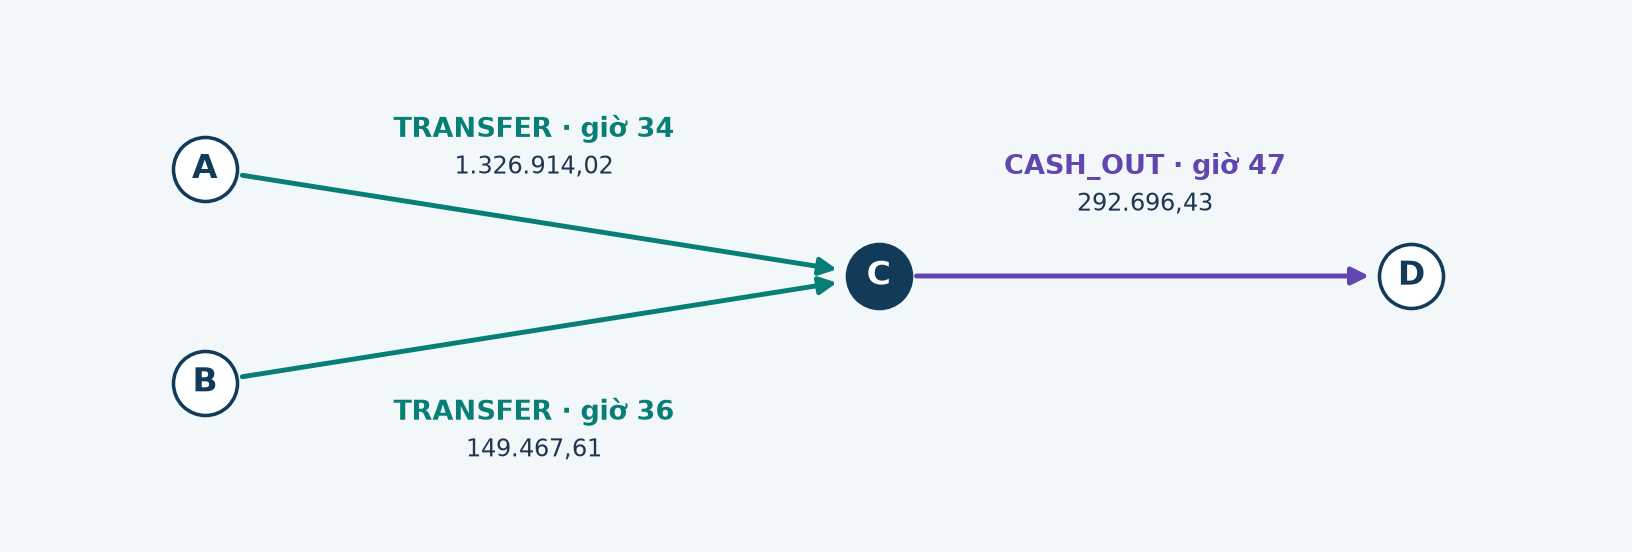

*Mỗi vòng tròn là một tài khoản. Mũi tên đi từ tài khoản gửi tới tài khoản nhận. Màu xanh lục là `TRANSFER`, màu tím là `CASH_OUT`. Số tiền tính theo đơn vị PaySim. Hình chỉ gồm ba giao dịch được chọn.*

**Hình cho thấy gì?** Hai tài khoản A và B chuyển tiền vào C ở giờ 34 và 36. Sau giao dịch nhận thứ hai **11 giờ**, C thực hiện `CASH_OUT` đến D. Khi ghép các dòng theo tài khoản và thời gian, ta thấy C vừa nhận tiền từ hai nguồn vừa phát sinh giao dịch rút tiền sau đó.

**Điều này giúp gì cho bài toán?** Số giao dịch đến C trong một khoảng thời gian trước khi rút là một thông tin có thể đưa vào mô hình. Cả ba giao dịch trong hình đều có nhãn gốc `isFraud = 0`. Ta sẽ kiểm tra trên tập đánh giá xem lịch sử như vậy có giúp phân biệt giao dịch fraud với các giao dịch còn lại hay không.

<details>
<summary>Nguồn và mã tài khoản trong hình</summary>
<p>Hai cặp tại giờ chuyển 34 và 36 trong <code>baseline_examples.csv</code> của run PaySim <code>run_20261024T084918669391Z</code>. Hai cặp cùng chứa giao dịch CASH_OUT giờ 47, được vẽ một lần.</p>
<ul><li>A = C831358900</li><li>B = C1554009922</li><li>C = C874023329</li><li>D = C1468339976</li></ul>
</details>

### Bài toán của nhóm

Với **mỗi giao dịch** trong dữ liệu mô phỏng PaySim, nhóm xây mô hình chấm điểm để ưu tiên giao dịch cần xem xét. Nhãn `isFraud` cho biết giao dịch nào được PaySim đánh dấu là gian lận. Nhóm so sánh mô hình chỉ biết thông tin giao dịch hiện tại với mô hình có thêm thông tin từ lịch sử.

| Bước | Câu hỏi cần trả lời |
| --- | --- |
| **Data** | Dữ liệu có những loại giao dịch nào? Mỗi dòng được chuyển thành cạnh có hướng ra sao? |
| **Degree và PageRank** | Giao dịch tập trung ở những tài khoản nào? Các tài khoản nổi bật chủ yếu gửi hay nhận? |
| **Motif finding** | Mạng có những mẫu giao dịch nào, chẳng hạn nhiều nguồn gửi vào một tài khoản hoặc chuyển tiền qua trung gian rồi rút? |
| **LPA** | Những tài khoản nào được xếp cùng nhóm? Giao dịch diễn ra bên trong nhóm hay qua biên nhóm? |
| **Features, model và đánh giá** | Thông tin nào có sẵn tại lúc chấm điểm? Thêm lịch sử đồ thị giúp phát hiện được bao nhiêu fraud và tạo thêm bao nhiêu cảnh báo sai? |

Phần Data sẽ quay lại cụm A–D để chỉ ra mỗi tài khoản và giao dịch được biểu diễn thế nào trong đồ thị.

Chỉ cần gửi notebook này: dữ liệu phân tích, code, bảng và hình đều nằm trong file. **Các ô code tạo bảng chạy được**: chúng đọc CSV/Parquet nhúng, rồi nhóm, lọc, tính tỷ lệ hoặc tái hiện thuật toán trên các mạng con đầy đủ. Các đoạn Spark ghi “CODE CHÍNH” trình bày cách chạy pipeline toàn dữ liệu. Bảng thuộc lần chạy toàn hệ thống được đọc từ kết quả đã lưu, không khởi động Spark khi trình bày. Bấm **Run All** để tính lại các bảng phân tích; các output cũng đã được lưu sẵn.

<a id="data"></a>

## 2. Data

Một dòng PaySim ghi một giao dịch mô phỏng. `step` là giờ mô phỏng, `amount` là số tiền theo đơn vị PaySim và `isFraud` là nhãn của giao dịch. Phần này đi từ **khám phá dữ liệu (EDA) → chuẩn hóa (ETL) → dựng đồ thị**.

### 2.1. EDA · Dữ liệu có đặc điểm gì?

Các bảng và biểu đồ dưới đây tóm tắt toàn bộ **6.362.620 giao dịch**. Bốn câu hỏi lần lượt xét loại giao dịch, số tiền, thời gian và vai trò của tài khoản.

In [1]:
# CODE CHÍNH
from pyspark.sql import functions as F

schema = (
    "step INT, type STRING, amount DOUBLE, nameOrig STRING, "
    "oldbalanceOrg DOUBLE, newbalanceOrig DOUBLE, nameDest STRING, "
    "oldbalanceDest DOUBLE, newbalanceDest DOUBLE, isFraud SMALLINT, "
    "isFlaggedFraud SMALLINT"
)
raw = spark.read.csv("PS_20174392719_1491204439457_log.csv", header=True, schema=schema)

#### Đọc đúng các trường trước khi đọc đồ thị

PaySim mô phỏng dịch vụ **mobile money**. Customer là khách hàng sử dụng dịch vụ, merchant là bên bán hàng/cung cấp dịch vụ. Mã `C` và `M` mô tả loại đối tượng; vai trò ở đầu nguồn/đích được xác định trên từng dòng.

| Trường gốc | Ý nghĩa và cách dùng |
| --- | --- |
| `step` | Giờ mô phỏng; dùng để sắp thời gian và giới hạn lịch sử. |
| `type` | Loại nghiệp vụ; cần đọc trước khi diễn giải chiều tiền. |
| `amount` | Giá trị giao dịch theo đơn vị PaySim; không mặc định là VND hay USD. |
| `nameOrig`, `nameDest` | Hai đối tượng được ghi ở đầu nguồn và đầu đích. Chúng tạo `src → dst` của đồ thị. |
| `oldbalanceOrg`, `newbalanceOrig` | Số dư trước/sau ở đầu nguồn. Giữ đúng tên `oldbalanceOrg` trong CSV. |
| `oldbalanceDest`, `newbalanceDest` | Số dư trước/sau ở đầu đích. Số 0 của merchant cần đọc cùng giới hạn dữ liệu. |
| `isFraud` | Nhãn fraud của mô phỏng, dùng để hậu kiểm và đánh giá model. |
| `isFlaggedFraud` | Cờ do cơ chế kiểm soát trong mô phỏng bật; phải phân biệt với nhãn fraud. |

`CASH_IN`: nạp tiền, số dư của khách hàng khởi tạo tăng. `CASH_OUT`: rút tiền. `PAYMENT`: trả tiền hàng/dịch vụ. `TRANSFER`: chuyển cho người dùng khác. `DEBIT`: chuyển từ dịch vụ mobile money sang tài khoản ngân hàng theo mô tả simulator. [Nguồn: bài PaySim gốc](https://www.msc-les.org/proceedings/emss/2016/EMSS2016_249.pdf).

**Hệ quả khi đọc graph:** in-degree đếm số dòng xuất hiện ở `nameDest`, out-degree đếm số dòng xuất hiện ở `nameOrig`. Trên mạng gộp nhiều loại, cần xem `type` trước khi gọi các cạnh vào/ra là tiền nhận/gửi. Bảng sau tính biến động số dư của từng ví dụ thực tế.

<table class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th>Loại giao dịch</th>
      <th>nameOrig</th>
      <th>nameDest</th>
      <th>amount</th>
      <th>oldbalanceOrg</th>
      <th>newbalanceOrig</th>
      <th>Biến động số dư nguồn</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>PAYMENT</td>
      <td>C1231006815</td>
      <td>M1979787155</td>
      <td>9.839,640000</td>
      <td>170.136,000000</td>
      <td>160.296,360000</td>
      <td>-9.839,640000</td>
    </tr>
    <tr>
      <td>TRANSFER</td>
      <td>C1305486145</td>
      <td>C553264065</td>
      <td>181,000000</td>
      <td>181,000000</td>
      <td>0,000000</td>
      <td>-181,000000</td>
    </tr>
    <tr>
      <td>CASH_OUT</td>
      <td>C840083671</td>
      <td>C38997010</td>
      <td>181,000000</td>
      <td>181,000000</td>
      <td>0,000000</td>
      <td>-181,000000</td>
    </tr>
    <tr>
      <td>DEBIT</td>
      <td>C712410124</td>
      <td>C195600860</td>
      <td>5.337,770000</td>
      <td>41.720,000000</td>
      <td>36.382,230000</td>
      <td>-5.337,770000</td>
    </tr>
    <tr>
      <td>CASH_IN</td>
      <td>C1862994526</td>
      <td>C1688019098</td>
      <td>143.236,260000</td>
      <td>0,000000</td>
      <td>143.236,260000</td>
      <td>143.236,260000</td>
    </tr>
  </tbody>
</table>

<table class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th>Loại mã</th>
      <th>Chỉ nameDest</th>
      <th>Chỉ nameOrig</th>
      <th>Cả hai đầu</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>C</td>
      <td>570.192</td>
      <td>6.351.538</td>
      <td>1.769</td>
    </tr>
    <tr>
      <td>M</td>
      <td>2.150.401</td>
      <td>0</td>
      <td>0</td>
    </tr>
  </tbody>
</table>

<table class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th>Loại giao dịch</th>
      <th>Loại mã</th>
      <th>Giao dịch</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>CASH_IN</td>
      <td>C</td>
      <td>1.399.284</td>
    </tr>
    <tr>
      <td>CASH_OUT</td>
      <td>C</td>
      <td>2.237.500</td>
    </tr>
    <tr>
      <td>DEBIT</td>
      <td>C</td>
      <td>41.432</td>
    </tr>
    <tr>
      <td>PAYMENT</td>
      <td>M</td>
      <td>2.151.495</td>
    </tr>
    <tr>
      <td>TRANSFER</td>
      <td>C</td>
      <td>532.909</td>
    </tr>
  </tbody>
</table>

Ví dụ `CASH_IN` cho thấy số dư ở `nameOrig` tăng đúng bằng `amount`. Trong file này, các giao dịch có đích `M` đều là `PAYMENT`; nhiều mã `C` cũng xuất hiện ở đầu đích. Các biểu đồ dùng mũi tên theo hai trường tên trong CSV. Khi bàn về dòng tiền, ta giới hạn vào loại nghiệp vụ phù hợp.

#### Loại giao dịch và nhãn fraud

Đếm giao dịch theo loại và chia số fraud cho tổng số giao dịch của từng loại. Cột tỷ lệ giúp so sánh các loại có quy mô khác nhau.

In [2]:
# CODE CHÍNH
by_type = raw.groupBy("type").agg(
    F.count("*").alias("transactions"), F.sum("isFraud").alias("fraud")
)
by_type = by_type.withColumn("fraud_rate", F.col("fraud") / F.col("transactions"))

Loại giao dịch,Giao dịch,GD fraud,Fraud (%)
CASH_OUT,2.237.500,4.116,"0,183955"
PAYMENT,2.151.495,0,"0,000000"
CASH_IN,1.399.284,0,"0,000000"
TRANSFER,532.909,4.097,"0,768799"
DEBIT,41.432,0,"0,000000"


Toàn bộ **8.213 giao dịch có nhãn fraud** nằm ở `TRANSFER` và `CASH_OUT`, chiếm khoảng **0,129%** toàn bộ dữ liệu. `TRANSFER` ít giao dịch hơn `CASH_OUT` nhưng có số fraud gần bằng, nên tỷ lệ fraud của loại này cao hơn. Hai loại này cũng là hai bước trong mẫu chuyển tiền rồi rút tiền sẽ được phân tích ở phần motif.

#### Số tiền theo nhãn

So sánh trung vị và hai phân vị cao của `amount` giữa các giao dịch có nhãn 0 và nhãn 1. Ví dụ, phân vị 90% là mốc mà khoảng 90% giao dịch trong nhóm có số tiền bằng hoặc thấp hơn.

In [3]:
# CODE CHÍNH
by_label = raw.groupBy("isFraud").agg(
    F.percentile("amount", [0.50, 0.90, 0.99]).alias("amount_quantiles")
)

Nhãn fraud,Giao dịch,Trung vị,Phân vị 90%,Phân vị 99%
0,6.354.407,"74.684,720000","364.373,444000","1.586.064,173400"
1,8.213,"441.423,440000","4.521.723,512000","10.000.000,000000"


Trong PaySim, trung vị số tiền của nhóm fraud là khoảng **441 nghìn**, so với **75 nghìn** ở nhóm còn lại. Cả hai nhóm đều có giao dịch giá trị lớn. Khi đọc khác biệt này cần xét cả loại giao dịch, vì nhóm fraud chỉ gồm `TRANSFER` và `CASH_OUT`, còn nhóm nhãn 0 có đủ năm loại.

#### Lượng giao dịch và tỷ lệ fraud theo thời gian

Gom theo khoảng 24 giờ mô phỏng. Khoảng cuối có 23 giờ. Biểu đồ dưới dùng các vạch theo bội số để nhìn được cả tỷ lệ nhỏ lẫn các đỉnh cao. Vạch đứt đánh dấu hết giờ 355, mốc phân tách tập đánh giá sau này.

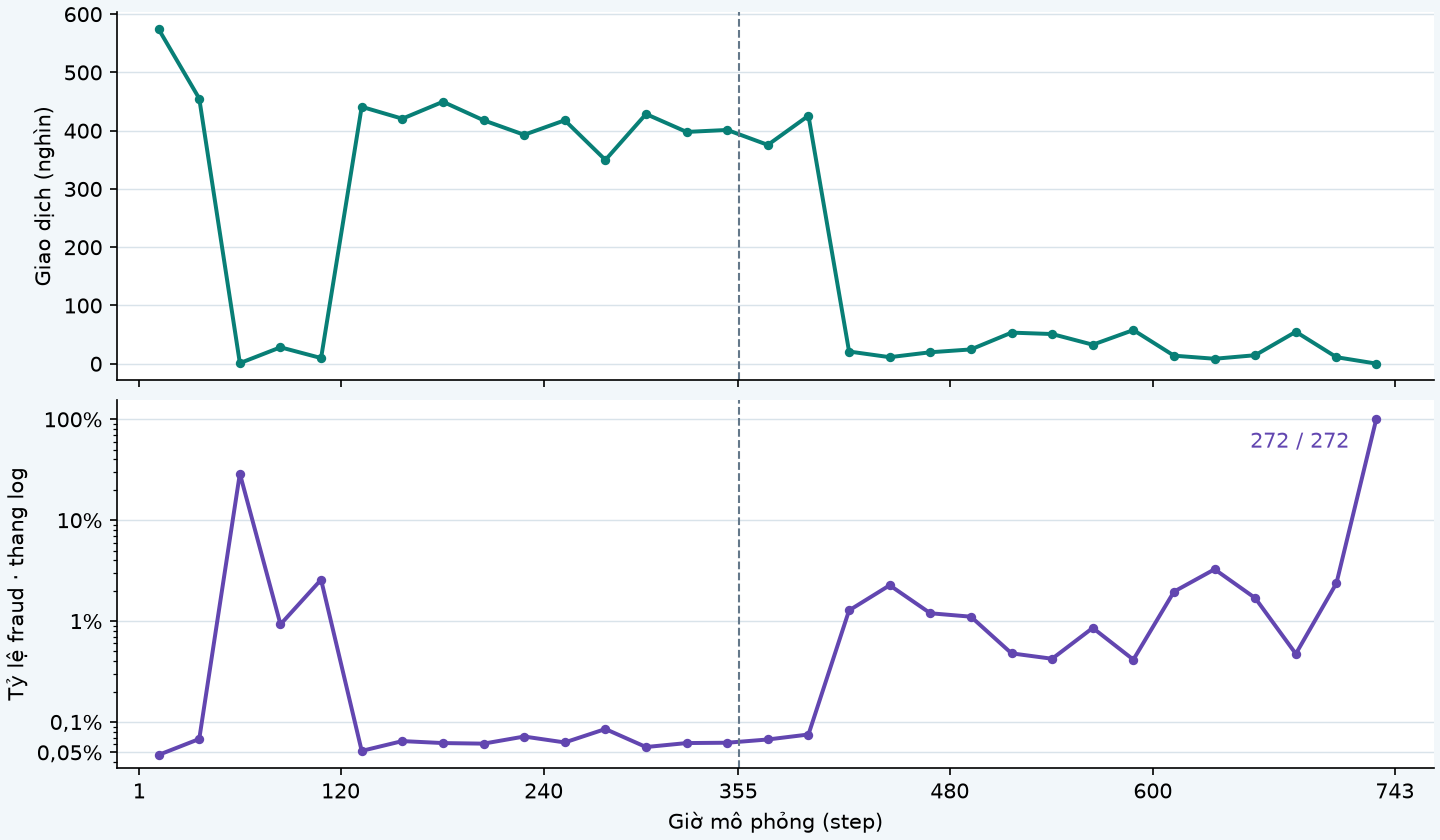

In [4]:
# CODE CHÍNH
start_hour = F.floor((F.col("step") - 1) / 24) * 24 + 1
timeline = raw.groupBy(start_hour.alias("start_hour")).agg(
    F.count("*").alias("transactions"), F.avg("isFraud").alias("fraud_rate")
)

Lượng giao dịch và tỷ lệ fraud biến động theo thời gian. Ví dụ, khoảng **721–743** có tỷ lệ 100% với **272 giao dịch**, trong khi nhiều khoảng trước có hàng trăm nghìn giao dịch. Khi gộp dữ liệu, tỷ lệ fraud ở giờ **304–355** là **0,056%**, còn giờ **356–743** là **0,340%**. Khác biệt này là lý do nhóm xem kết quả model trên các giao dịch xảy ra sau mốc huấn luyện và xem thêm kết quả theo từng giai đoạn.

### 2.2. ETL · Vì sao cần chuẩn hóa?

Quay lại đúng ba dòng CSV của cụm A–D. Bảng giữ các cột cần để theo dõi một giao dịch từ dữ liệu gốc sang bảng cạnh.

<table class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th>nameOrig</th>
      <th>nameDest</th>
      <th>Loại giao dịch</th>
      <th>step</th>
      <th>amount</th>
      <th>Nhãn fraud</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>C831358900</td>
      <td>C874023329</td>
      <td>TRANSFER</td>
      <td>34</td>
      <td>1.326.914,020000</td>
      <td>0</td>
    </tr>
    <tr>
      <td>C1554009922</td>
      <td>C874023329</td>
      <td>TRANSFER</td>
      <td>36</td>
      <td>149.467,610000</td>
      <td>0</td>
    </tr>
    <tr>
      <td>C874023329</td>
      <td>C1468339976</td>
      <td>CASH_OUT</td>
      <td>47</td>
      <td>292.696,430000</td>
      <td>0</td>
    </tr>
  </tbody>
</table>

| Thao tác | Vì sao cần làm? |
| --- | --- |
| Đổi `nameOrig` thành `src` và `nameDest` thành `dst` | Đặt tên hai đầu cạnh theo schema đồ thị; diễn giải chiều tiền theo type. |
| Chuẩn hóa kiểu của `step` và `amount`, giữ `type` | So sánh thời gian và số tiền theo giá trị số. Giữ loại để phân biệt các bước như chuyển tiền và rút tiền. |
| Giữ `isFraud` trên từng giao dịch | Đối chiếu các kết quả phân tích và làm nhãn khi huấn luyện model. |
| Giữ từng dòng khi tạo cạnh | Mỗi lần giao dịch giữ được loại, giờ, số tiền và nhãn của chính nó. |


Đoạn code dưới ánh xạ từng dòng thành một cạnh, sau đó hợp hai cột mã tài khoản để dựng bảng đỉnh. Với mỗi tài khoản, `max_by` lấy số dư sau giao dịch ở giờ gần nhất. Bảng kết quả trích ba cạnh của cụm A–D.

In [6]:
# CODE CHÍNH
# Mỗi dòng CSV trở thành một cạnh có hướng.
edges = raw.select(
    F.col("nameOrig").alias("src"), F.col("nameDest").alias("dst"),
    F.col("amount").cast("double").alias("amount"),
    F.col("step").cast("int").alias("step"), "type",
    F.col("isFraud").cast("short").alias("isFraud"),
)

# Gom cả hai đầu giao dịch để mỗi tài khoản có đúng một đỉnh.
senders = raw.select(F.col("nameOrig").alias("id"),
                     F.col("newbalanceOrig").alias("balance"), "step")
receivers = raw.select(F.col("nameDest").alias("id"),
                       F.col("newbalanceDest").alias("balance"), "step")
vertices = (senders.unionByName(receivers).groupBy("id")
    .agg(F.max_by("balance", "step").alias("balance"))
    .withColumn("account_type", F.when(F.col("id").startswith("C"), "Customer")
        .when(F.col("id").startswith("M"), "Merchant").otherwise("Unknown"))
    .select("id", "account_type", "balance"))

src,dst,Loại giao dịch,step,amount,Nhãn fraud
C831358900,C874023329,TRANSFER,34,"1.326.914,020000",0
C1554009922,C874023329,TRANSFER,36,"149.467,610000",0
C874023329,C1468339976,CASH_OUT,47,"292.696,430000",0


Ba giao dịch giữ nguyên đầu gửi, đầu nhận, loại, giờ, số tiền và nhãn. Từ đây mọi thuật toán có thể dùng chung hai cột `src` và `dst` để đọc hướng giao dịch.

Gộp tất cả `src` và `dst`, rồi lấy mỗi mã tài khoản một lần để tạo bảng đỉnh. Mỗi giao dịch trong bảng cạnh tạo một mũi tên từ đỉnh gửi tới đỉnh nhận. Sơ đồ dưới đây lấy hướng, loại, giờ và số tiền từ bảng cạnh vừa tạo.

### 2.3. Graph construction · Từ bảng cạnh đến đồ thị



id
C831358900
C1554009922
C874023329
C1468339976


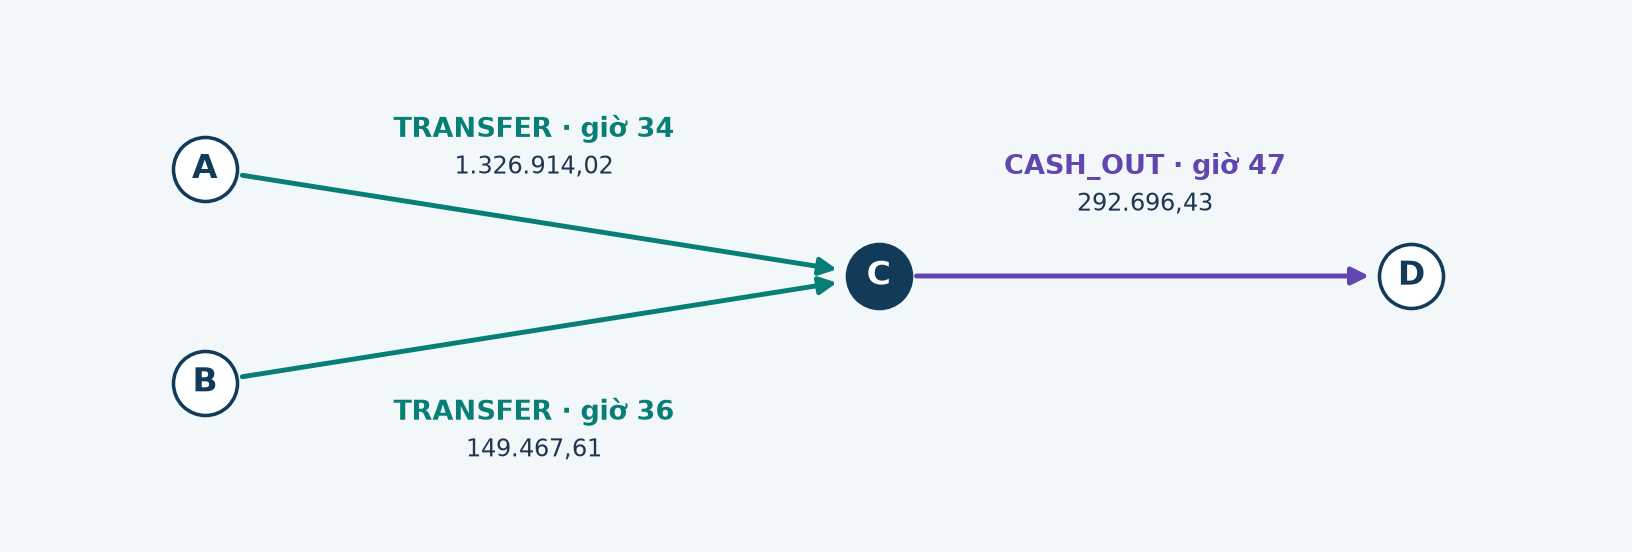

In [7]:
# CODE CHÍNH
from graphframes import GraphFrame

graph = GraphFrame(vertices, edges)
edges.write.parquet("edges.parquet")
vertices.write.parquet("vertices.parquet")

*Hình gồm 4 đỉnh và 3 cạnh của cụm A–D. Màu xanh lục là `TRANSFER`, màu tím là `CASH_OUT`. Số tiền theo đơn vị PaySim.*

C xuất hiện ở cả đầu nhận lẫn đầu gửi nhưng chỉ tạo **một đỉnh**. Vì vậy, hai cạnh đi vào và một cạnh đi ra gặp nhau tại C. Đây là cách đồ thị giữ quan hệ giữa các dòng vốn nằm riêng trong CSV.

Trên toàn bộ dữ liệu, nhóm đối chiếu các giao dịch sau ánh xạ với Parquet theo cả hai chiều, rồi kiểm tra mỗi đầu cạnh có mã tương ứng trong bảng đỉnh.

In [8]:
# CODE CHÍNH
# So sánh hai chiều và giữ số lần xuất hiện của từng dòng.
saved_edges = spark.read.parquet("edges.parquet").select(*edges.columns)
saved_vertices = spark.read.parquet("vertices.parquet")
missing = edges.exceptAll(saved_edges).count()
extra = saved_edges.exceptAll(edges).count()

ids = saved_vertices.select("id")
dangling_src = saved_edges.join(ids, saved_edges.src == ids.id, "left_anti").count()
dangling_dst = saved_edges.join(ids, saved_edges.dst == ids.id, "left_anti").count()
self_loops = saved_edges.where("src = dst").count()

check,value
num_vertices,9.073.900
num_edges,6.362.620
null_vertices,0
null_edges,0
dangling_src,0
dangling_dst,0
dangling_edges,0
self_loops,0


table,raw_minus_parquet,parquet_minus_raw,status
edges,0,0,PASS
vertices_id_type,0,0,PASS


Kết quả lưu từ lần chạy gốc ghi nhận **6.362.620 cạnh**, khớp với số dòng giao dịch. Đối chiếu sau ánh xạ cho **0 chênh lệch theo cả hai chiều**, và tất cả đầu cạnh đều có đỉnh tương ứng. Từ đồ thị có hướng này, phần sau sẽ đọc tài khoản nào gửi hoặc nhận nhiều, mẫu giao dịch nào xuất hiện và LPA xếp các tài khoản vào nhóm ra sao.

<details>
<summary>Nguồn số liệu và phạm vi tính</summary>
<p>Thống kê loại, nhãn, thời gian, vai trò và phân vị được tính trên CSV PaySim đã đối chiếu SHA-256 với dữ liệu của run <code>run_20261024T084918669391Z</code>. Phân vị amount tính riêng theo <code>isFraud</code> với nội suy tuyến tính. Ba dòng minh họa được đối chiếu theo đầu gửi, đầu nhận, loại, step, amount và nhãn với ví dụ relay đã lưu.</p>
<p>Số đỉnh/cạnh, chênh lệch CSV–Parquet và phân bố degree lấy từ <code>report.json</code>, <code>raw_reconciliation.json</code> và <code>degree_distribution.csv</code> của run gốc.</p>
</details>

<a id="thuat-toan-do-thi"></a>

## 3. Thuật toán đồ thị

Từ bảng đỉnh và cạnh, nhóm đọc cùng một mạng theo bốn góc nhìn. **Degree** đếm giao dịch vào và ra. **PageRank** tìm tài khoản nổi bật theo liên kết đến. **Motif finding** tìm các mẫu giao dịch. **LPA** gom tài khoản theo nhãn lan truyền từ hàng xóm.

Các bảng toàn mạng mô tả lịch sử PaySim đã quan sát. Khi chấm điểm giao dịch mới, mô hình cần tính đặc trưng từ thông tin có trước giao dịch đó. Phần 4 sẽ nối hai bước này.

### 3.1. Degree · Giao dịch tập trung ở những tài khoản nào?

Gom theo `dst` để đếm giao dịch đi vào, gom theo `src` để đếm giao dịch đi ra. Ghép hai số đếm vào danh sách tài khoản, điền 0 ở phía thiếu rồi cộng lại thành `degree`. Biểu đồ dùng thang log để nhìn được cả nhóm rất đông lẫn nhóm ít tài khoản.

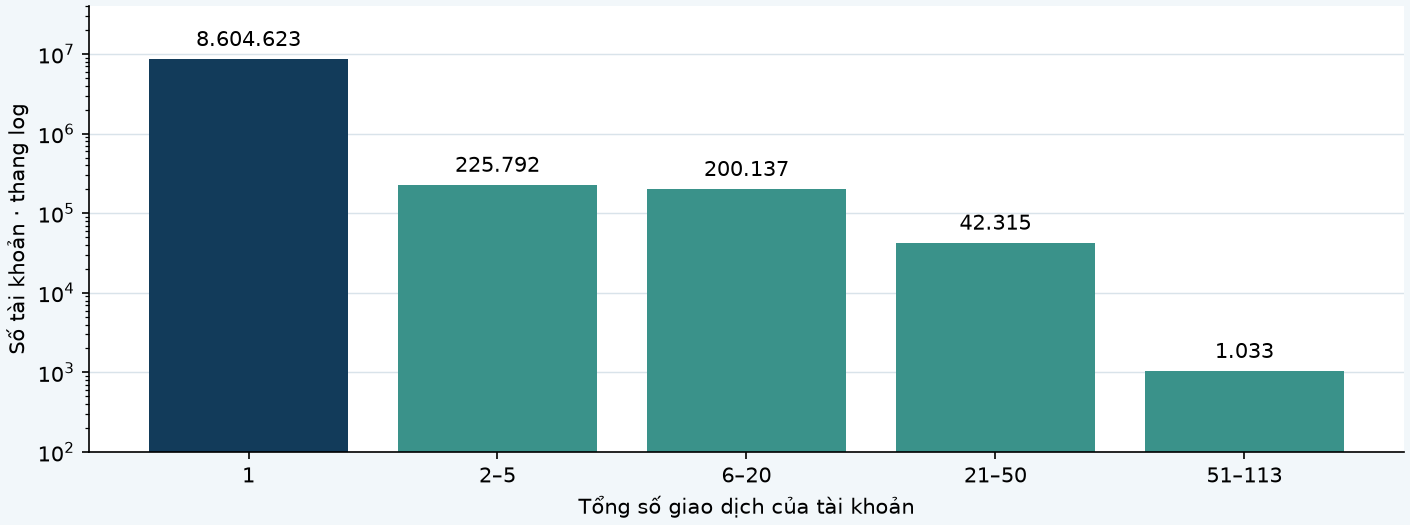

In [9]:
# CODE CHÍNH
def degree_by_account(vertices, edges):
    ids = vertices.select("id")
    incoming = edges.groupBy("dst").agg(F.count("*").alias("inDegree"))
    outgoing = edges.groupBy("src").agg(F.count("*").alias("outDegree"))

    degree = (ids
        .join(incoming.withColumnRenamed("dst", "id"), "id", "left")
        .join(outgoing.withColumnRenamed("src", "id"), "id", "left")
        .fillna(0, subset=["inDegree", "outDegree"])
        .withColumn("degree", F.col("inDegree") + F.col("outDegree")))
    return degree

degree = degree_by_account(vertices, edges)
degree_distribution = degree.groupBy("degree").count()

Có **8.604.623 tài khoản chỉ xuất hiện trong một giao dịch**, chiếm **94,8%** toàn mạng. Ở đầu kia của phân bố, tài khoản có degree cao nhất xuất hiện trong **113 giao dịch**. Để biết tài khoản hoạt động nhiều đang gom giao dịch hay phân phối giao dịch, cần tách cạnh vào và cạnh ra.



#### Toàn mạng trước, ví dụ sau: chọn nhóm có phiến diện không?

Trước khi nhìn nhãn fraud, chia **mọi tài khoản** theo số lần xuất hiện ở hai đầu. Các dải in-degree giữ cả vùng thấp và cao; out-degree giữ từng giá trị vì tối đa chỉ là 3. Mỗi tài khoản thuộc đúng một ô. Bảng này mô tả toàn population, không phụ thuộc vào tài khoản được chọn để vẽ.

<table class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th>inDegree / outDegree</th>
      <th>0</th>
      <th>1</th>
      <th>2</th>
      <th>3</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>0</td>
      <td>0</td>
      <td>6.342.242</td>
      <td>9.281</td>
      <td>15</td>
    </tr>
    <tr>
      <td>1</td>
      <td>2.262.381</td>
      <td>323</td>
      <td>0</td>
      <td>0</td>
    </tr>
    <tr>
      <td>2–5</td>
      <td>215.608</td>
      <td>670</td>
      <td>1</td>
      <td>0</td>
    </tr>
    <tr>
      <td>6–20</td>
      <td>199.414</td>
      <td>638</td>
      <td>0</td>
      <td>0</td>
    </tr>
    <tr>
      <td>21–50</td>
      <td>42.161</td>
      <td>132</td>
      <td>1</td>
      <td>0</td>
    </tr>
    <tr>
      <td>51+</td>
      <td>1.029</td>
      <td>4</td>
      <td>0</td>
      <td>0</td>
    </tr>
  </tbody>
</table>

Hai ví dụ dưới đây đều là điểm nhận nhiều giao dịch. Một tài khoản có degree cao nhất toàn mạng. Tài khoản còn lại nhận 89 giao dịch, trong đó có một `CASH_OUT` mang nhãn fraud.

Hai hình hub là ví dụ phóng to. Các bảng population và kiểm tra nhiều mức top-K dưới đây cung cấp căn cứ cho nhận định chung.

<table class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th>id</th>
      <th>In-degree</th>
      <th>Out-degree</th>
      <th>Tổng amount trên cạnh vào</th>
      <th>Fraud ở cạnh vào</th>
      <th>Loại cạnh vào và số lượng</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>C1286084959</td>
      <td>113</td>
      <td>0</td>
      <td>77.428.943,310000</td>
      <td>0</td>
      <td>NaN</td>
    </tr>
    <tr>
      <td>C716083600</td>
      <td>89</td>
      <td>0</td>
      <td>62.897.438,150000</td>
      <td>1</td>
      <td>NaN</td>
    </tr>
  </tbody>
</table>

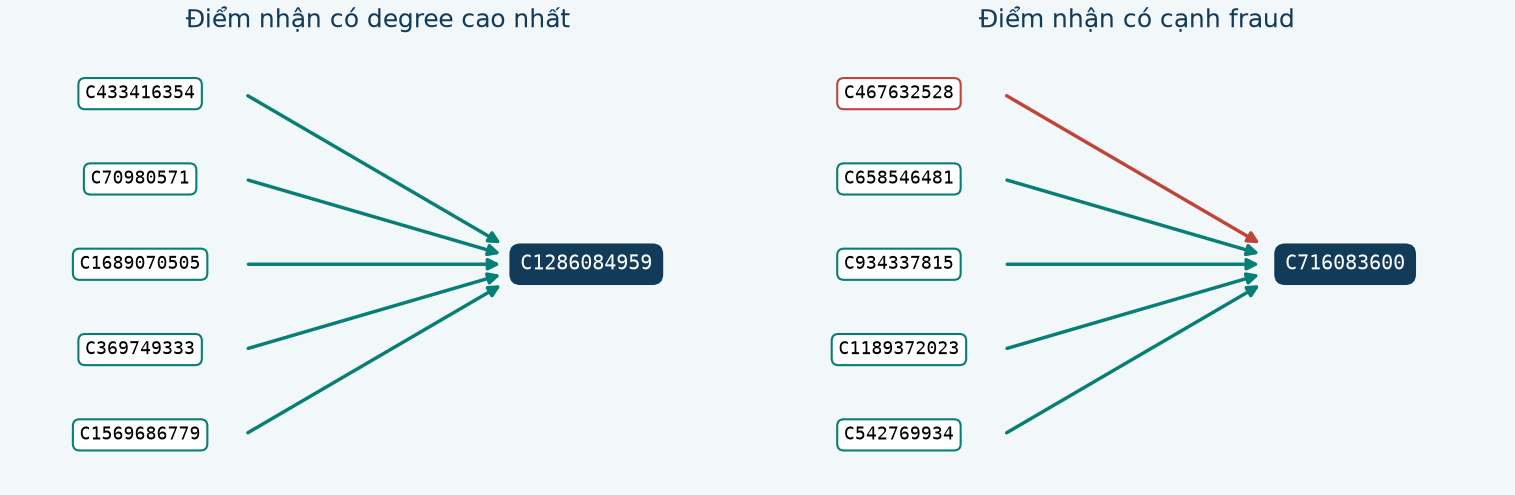

*Mỗi hình hiển thị 5 cạnh đi vào tài khoản ở ô đậm. Chọn cạnh fraud trước nếu có, sau đó chọn theo số tiền giảm dần. Mũi tên đỏ có nhãn `isFraud = 1`, mũi tên xanh có nhãn 0. Bảng tính trên toàn bộ giao dịch của hai tài khoản. Số tiền theo đơn vị PaySim.*

Cả **C1286084959** và **C716083600** đều có nhiều nguồn gửi vào và không có cạnh ra. Tài khoản thứ nhất nhận 113 giao dịch có nhãn 0. Tài khoản thứ hai nhận một giao dịch fraud trong 89 giao dịch. Nhìn degree, ta nhận ra vai trò **điểm đích có nhiều cạnh vào**. Nhìn thêm từng cạnh và nhãn, ta thấy hai điểm nhận có hoạt động khác nhau.

### 3.2. PageRank · Có thấy những tài khoản khác với degree không?

Mỗi tài khoản bắt đầu với điểm 1. Trong mỗi vòng, tài khoản gửi chia điểm theo số giao dịch đi ra, còn tài khoản nhận cộng phần điểm từ các nguồn gửi vào. Pipeline cập nhật 10 vòng rồi chuẩn hóa điểm. Bản chạy toàn mạng lưu từng vòng ra Parquet để quản lý bộ nhớ. Bảng bên dưới trích năm tài khoản đứng đầu.

$$\mathrm{PR}^{(k+1)}(u) = \frac{1 - d}{|V|} + d \sum_{v \in \mathcal{N}_{\mathrm{in}}(u)} \frac{\mathrm{PR}^{(k)}(v)}{d_{\mathrm{out}}(v)}$$


In [10]:
# CODE CHÍNH
def pagerank_by_account(vertices, edges):
    ids = vertices.select("id")
    # Phần điểm chuyển đến mỗi đích dựa trên số giao dịch.
    links = edges.groupBy("src", "dst").agg(F.count("*").alias("multiplicity"))
    outgoing = links.groupBy("src").agg(F.sum("multiplicity").alias("outgoing"))
    weights = links.join(outgoing, "src").select(
        "src", "dst", (F.col("multiplicity") / F.col("outgoing")).alias("weight")
    )

    ranks = ids.withColumn("pagerank", F.lit(1.0))
    for _ in range(10):
        # Lấy điểm của nguồn rồi cộng phần điểm chuyển vào mỗi đích.
        sources = ranks.withColumnRenamed("id", "src")
        incoming = (weights.join(sources, "src").groupBy("dst")
            .agg(F.sum(F.col("pagerank") * F.col("weight")).alias("incoming")))
        ranks = (ids.join(incoming.withColumnRenamed("dst", "id"), "id", "left")
            .select("id", (0.15 + 0.85 * F.coalesce(F.col("incoming"), F.lit(0.0)))
                    .alias("pagerank")))

    totals = ranks.agg(F.count("*").alias("n"), F.sum("pagerank").alias("total")).first()
    ranks = ranks.withColumn("pagerank", F.col("pagerank") * F.lit(totals.n / totals.total))
    return ranks

ranks = pagerank_by_account(vertices, edges)
top_pagerank = ranks.join(degree, "id").orderBy(F.desc("pagerank"), "id").limit(10)

Mốc phân vị,PageRank
min,"0,626485"
p50,"0,626485"
p90,"1,158997"
p99,"8,081658"
max,"60,800382"


Tỷ lệ chọn dự kiến,Ngưỡng PageRank,Tài khoản,Tỷ lệ tài khoản thực tế,Tỷ lệ tổng điểm,Tỷ lệ cạnh vào
0.10%,"19,264418",9.468,0.10%,2.41%,6.25%
1.00%,"8,081658",92.184,1.02%,12.89%,32.74%
5.00%,"1,691510",459.700,5.07%,27.26%,64.43%
10.00%,"1,158997",2.715.724,29.93%,56.08%,99.90%


id,PageRank,In-degree,Out-degree,degree
C1286084959,"60,800382",113,0,113
C985934102,"58,670332",109,0,109
C665576141,"56,540283",105,0,105
C2083562754,"54,676490",102,0,102
C1590550415,"54,410234",101,0,101


Nhóm đích,Giao dịch,GD fraud,Tỷ lệ fraud,Fraud (%)
PR >= approximate p99,2.083.069,"1.737,000000",0.08%,"0,083387"
remaining,4.279.551,"6.476,000000",0.15%,"0,151324"


Khoảng **1,02% tài khoản** đạt hoặc vượt ngưỡng xấp xỉ p99, và chúng nhận **32,74% giao dịch**. Khi lập nhóm, phép đếm giữ cả các tài khoản có điểm bằng ngưỡng.

**Top 10 PageRank và top 10 total degree trùng cả 10 tài khoản.** Trong PaySim, PageRank và in-degree có tương quan Pearson **0,999**. Mạng quanh C1286084959 minh họa sự trùng nhau này. Tài khoản đứng đầu nhận 113 giao dịch từ 113 nguồn, còn chính nó không gửi giao dịch nào. PageRank xác nhận vị trí nổi bật của các điểm đích trong mạng này. Với danh sách top 10, hai thước đo đưa ta tới cùng các tài khoản.

Trong các giao dịch đi vào nhóm PageRank từ p99 trở lên, **1.737/2.083.069** có nhãn fraud, khoảng **0,083%**. Ở các tài khoản nhận còn lại, tỷ lệ là **6.476/4.279.551**, khoảng **0,151%**. Vì vậy, trên dữ liệu này, điểm PageRank cao phù hợp hơn để tìm nơi giao dịch tập trung. Khi thử làm feature, nhóm tính degree và PageRank của hai đầu giao dịch từ mạng lịch sử.

### 3.3. Motif finding · Quan hệ nào xuất hiện giữa các giao dịch?

Motif là một mẫu gồm nhiều cạnh. Nhóm ghép giao dịch qua tài khoản chung, sau đó áp điều kiện về hướng, loại giao dịch và thời gian tùy mẫu.

| Mẫu | Cách đọc |
| --- | --- |
| Chu trình 3 tài khoản | `A → B → C → A`. Ba cạnh tạo một vòng có hướng. |
| Hai chiều | `A → B` và `B → A`. Hai tài khoản giao dịch theo hai hướng ngược nhau. |
| Relay | `A → B → C`. Trong PaySim, xem `TRANSFER` vào tài khoản trung gian rồi `CASH_OUT` đi ra. |
| Fan-in | `A → C ← B`. Nhiều nguồn gửi vào cùng một tài khoản. |
| Fan-out | `B ← A → C`. Một nguồn gửi tới nhiều tài khoản khác nhau. |

Truy vấn ban đầu đếm chu trình trên toàn đồ thị. Với relay, truy vấn yêu cầu ba tài khoản phân biệt, mỗi giao dịch trên **10.000 đơn vị PaySim**, và `CASH_OUT` xảy ra cùng giờ hoặc trong 24 giờ sau `TRANSFER`.

In [11]:
# CODE CHÍNH
distinct_accounts = "a.id <> b.id AND b.id <> c.id AND a.id <> c.id"
cycle_pattern = "(a)-[e1]->(b);(b)-[e2]->(c);(c)-[e3]->(a)"
cycles = graph.find(cycle_pattern).where(distinct_accounts)

eligible_relay = edges.where(F.col("type").isin("TRANSFER", "CASH_OUT") & (F.col("amount") > 10_000))
relay_graph = GraphFrame(vertices, eligible_relay)
relays = (relay_graph.find("(a)-[e1]->(b);(b)-[e2]->(c)")
    .where(distinct_accounts)
    .where("e1.type = 'TRANSFER' AND e2.type = 'CASH_OUT'")
    .where("e2.step - e1.step BETWEEN 0 AND 24"))

dataset,raw_cycles,relay_pairs,same_hour
paysim,0,30,2


**Fan-in nhìn vào tài khoản nhận.** Hình bên trái lấy hai giao dịch đến C ở giờ 34 và 36. Hình bên phải chọn một `CASH_OUT` có nhãn fraud ở giờ 356 và tìm giao dịch từ một nguồn khác đến cùng tài khoản nhận, sớm hơn 2 giờ.

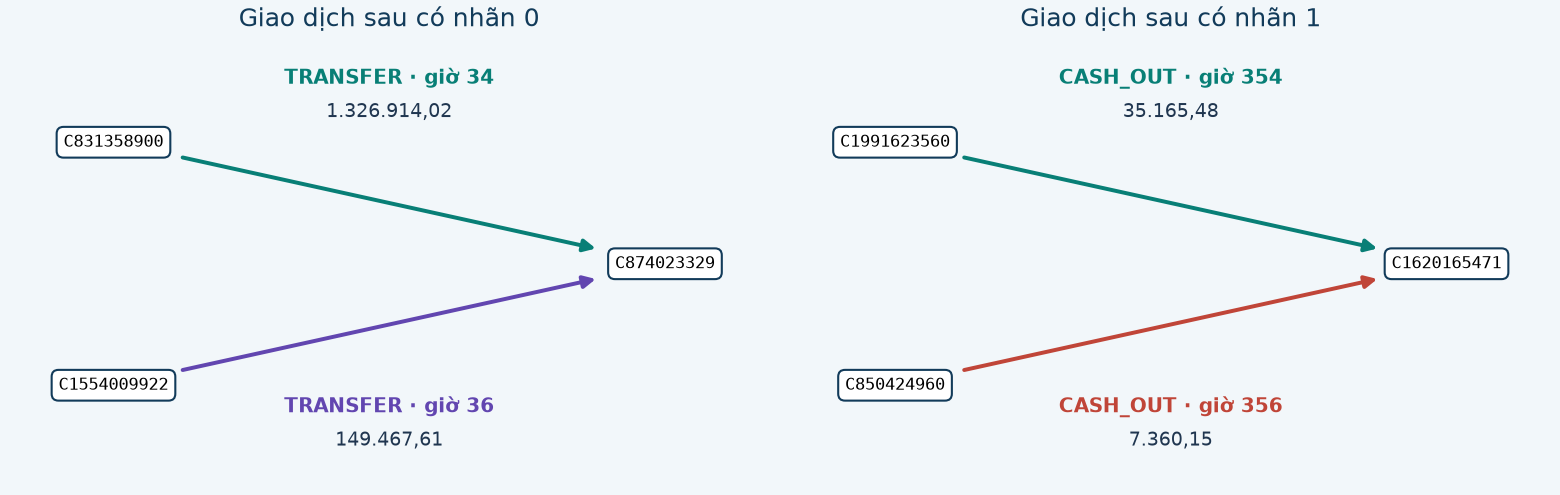

In [13]:
# CODE CHÍNH
# Chọn giao dịch giờ 356 trong hình, rồi tìm nguồn gửi trước đó.
current = eligible.where("src = 'C850424960' AND dst = 'C1620165471' AND step = 356").first()
fanin_history = past_edges(current, 168).where(
    (F.col("dst") == current.dst) & (F.col("src") != current.src)
)

*Trong từng hình, cạnh trên xuất hiện trước. Xanh là cạnh trước có nhãn 0, tím là cạnh sau có nhãn 0, đỏ là cạnh có nhãn fraud. Số tiền theo đơn vị PaySim.*

Hai ví dụ có cùng cấu trúc **nhiều nguồn → một đích**, với nhãn khác nhau ở giao dịch sau. Fan-in bổ sung bối cảnh của đầu nhận, chẳng hạn trước khi một `CASH_OUT` xảy ra, đã có giao dịch từ nguồn khác tới cùng đích hay chưa.

**Fan-out nhìn từ tài khoản gửi.** Hình bên trái là hai giao dịch `PAYMENT` tới hai bên nhận khác nhau, cách nhau 97 giờ. Hình bên phải có một `CASH_IN` và một `CASH_OUT` mang nhãn fraud, cách nhau 93 giờ và có hai đích khác nhau.

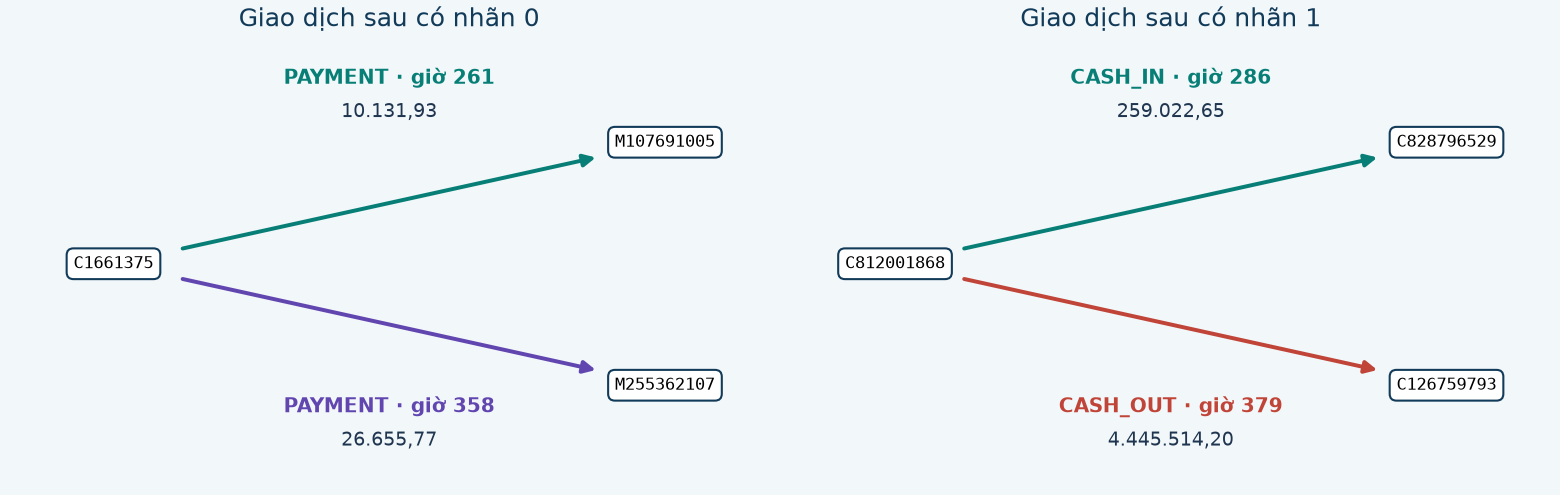

In [14]:
# CODE CHÍNH
current = eligible.where("src = 'C812001868' AND dst = 'C126759793' AND step = 379").first()
history = past_edges(current, 168)
fanout_history = history.where((F.col("src") == current.src) & (F.col("dst") != current.dst))
reciprocal_history = history.where((F.col("src") == current.dst) & (F.col("dst") == current.src))

*Màu và thứ tự cạnh giống hình fan-in. Cả hai cặp đều nằm trong cửa sổ lịch sử 168 giờ của giao dịch sau.*

Fan-out mô tả lịch sử **một nguồn → nhiều đích**. Hai ví dụ cho thấy cùng kiểu phân phối có thể xuất hiện ở giao dịch nhãn 0 lẫn nhãn 1. Ta cần xem mẫu xuất hiện ở bao nhiêu giao dịch trên tập đánh giá để biết tín hiệu này phổ biến đến đâu.

**So sánh các motif trên tập đánh giá.** Mỗi dòng đếm giao dịch có ít nhất một mẫu phù hợp từ lịch sử 168 giờ. Cột “% trên 4.250 fraud” cho biết mẫu hiện diện ở bao nhiêu phần trăm giao dịch fraud của tập đánh giá. Cột cuối đổi mẫu số sang toàn bộ giao dịch có tín hiệu để xem trong số đó có bao nhiêu fraud.

In [15]:
# CODE CHÍNH
from pyspark.sql import Window

# Cạnh ở giờ s được tính từ s+1 đến hết s+hours.
def past_count(history, queries, keys, hours, name):
    buckets = history.groupBy(*keys, "step").count()
    starts = buckets.select(*keys, (F.col("step") + 1).alias("t"), F.col("count").alias("delta"))
    ends = buckets.select(*keys, (F.col("step") + hours + 1).alias("t"), (-F.col("count")).alias("delta"))
    points = queries.select(*keys, F.col("step").alias("t"), F.lit(0).alias("delta")).distinct()
    grid = starts.unionByName(ends).unionByName(points).groupBy(*keys, "t").agg(F.sum("delta").alias("delta"))
    prefix = Window.partitionBy(*keys).orderBy("t").rowsBetween(Window.unboundedPreceding, Window.currentRow)
    grid = grid.select(*keys, F.col("t").alias("step"), F.sum("delta").over(prefix).alias(name))
    return queries.join(grid, [*keys, "step"]).select("event_id", name)

def motif_history(events, eligible):
    features = events
    transfers = eligible.where("type = 'TRANSFER'")
    reversed_edges = eligible.select(F.col("dst").alias("src"), F.col("src").alias("dst"), "step")
    reversed_transfers = transfers.select(F.col("dst").alias("src"), F.col("src").alias("dst"), "step")
    for h in (24, 168):
        sources = [
            ("sender_in", ["src"], eligible.select(F.col("dst").alias("src"), "step")),
            ("sender_out", ["src"], eligible),
            ("receiver_in", ["dst"], eligible),
            ("receiver_out", ["dst"], eligible.select(F.col("src").alias("dst"), "step")),
            ("same_partner", ["src", "dst"], eligible),
            ("reciprocal", ["src", "dst"], reversed_edges),
            ("transfer_in", ["src"], transfers.select(F.col("dst").alias("src"), "step")),
            ("reverse_transfer", ["src", "dst"], reversed_transfers),
        ]
        for stem, keys, history in sources:
            name = f"{stem}_{h}h"
            query = eligible.select("event_id", *keys, "step")
            features = features.join(past_count(history, query, keys, h, name), "event_id", "left").fillna(0, [name])

        same = F.col(f"same_partner_{h}h")
        features = (features
            .withColumn(f"fanin_{h}h", F.col(f"receiver_in_{h}h") - same)
            .withColumn(f"fanout_{h}h", F.col(f"sender_out_{h}h") - same)
            .withColumn(f"relay_{h}h", F.when(F.col("type") == "CASH_OUT",
                F.col(f"transfer_in_{h}h") - F.col(f"reverse_transfer_{h}h")).otherwise(0))
            .drop(f"same_partner_{h}h", f"transfer_in_{h}h", f"reverse_transfer_{h}h"))
    return features

# Với chu trình, cạnh thứ ba là giao dịch đang xét.
cycle_edges = (GraphFrame(vertices, eligible).find(cycle_pattern).where(distinct_accounts)
    .where("e1.step < e2.step AND e2.step < e3.step AND e3.step - e1.step <= 168"))
a, b, c = (F.col(f"e{i}.amount") for i in (1, 2, 3))
cycle_stats = cycle_edges.groupBy(F.col("e3.event_id").alias("event_id")).agg(
    F.count("*").alias("cycle3_count"),
    F.max(F.least(a, b, c) / F.greatest(a, b, c)).alias("cycle3_best_ratio"),
    F.min((F.col("e3.step") - F.col("e1.step")) * 3600).alias("cycle3_min_gap_seconds"),
)
motif_features = motif_history(unlabelled, eligible).join(cycle_stats, "event_id", "left").fillna(0)

test = motif_features.join(truth, "event_id").where("step > 355")
coverage = {}
for name in ("cycle3_count", "relay_168h", "reciprocal_168h", "fanin_168h", "fanout_168h"):
    has_motif = F.col(name) > 0
    coverage[name] = test.agg(
        F.count_if(has_motif).alias("covered_transactions"),
        F.count_if(has_motif & (F.col("isFraud") == 1)).alias("covered_fraud"),
    ).first()

Mẫu,GD có mẫu,Fraud có mẫu,Fraud được phủ (%),Fraud trong GD có mẫu (%)
Chu trình 3,0,0,"0,000000",NaN
Relay,21,0,"0,000000","0,000000"
Hai chiều,0,0,"0,000000",NaN
Fan-in,602.017,895,"21,058824","0,148667"
Fan-out,1.226,1,"0,023529","0,081566"


Fan-in xuất hiện ở **895/4.250 giao dịch fraud (21,06%)**. Nhưng trong **602.017** giao dịch có tín hiệu fan-in, chỉ **0,149%** mang nhãn fraud, thấp hơn mức **0,340%** của toàn tập đánh giá. Fan-out hiếm hơn và xuất hiện ở **1** giao dịch fraud. Relay xuất hiện ở **21** giao dịch trong cửa sổ này, tất cả đều có nhãn 0.

Truy vấn chu trình ba tài khoản trên toàn đồ thị cho **0** kết quả. Tín hiệu hai chiều trong cửa sổ đã xét cũng bằng **0**. Tỷ lệ trên các giao dịch có tín hiệu để trống ở hai dòng này vì mẫu số bằng 0. Các số liệu trên đo **mức hiện diện của motif**. Để đánh giá dự đoán, phần model sẽ đếm riêng cảnh báo đúng, cảnh báo sai và fraud bị bỏ sót.

### 3.4. LPA · Tài khoản cùng nhóm liên hệ với nhau thế nào?

LPA cập nhật nhãn tài khoản theo nhãn của hàng xóm. Lần chạy PaySim thực hiện **5 lượt**, rồi đếm thành viên theo nhãn cuối. Để đọc kết quả nghiệp vụ, nhóm đối chiếu cả hai đầu giao dịch. **Nội bộ** là hai đầu cùng nhóm. **Qua biên** là hai đầu khác nhóm.

In [16]:
# CODE CHÍNH
def propagate_labels(vertices, edges):
    # Một cạnh truyền phiếu theo cả hai hướng.
    links = (edges.select(F.col("src").alias("id"), F.col("dst").alias("neighbor"))
        .unionByName(edges.select(F.col("dst").alias("id"), F.col("src").alias("neighbor")))
        .groupBy("id", "neighbor").agg(F.count("*").alias("multiplicity")))
    labels = vertices.select("id").withColumn("label", F.xxhash64("id"))
    for _ in range(5):
        messages = links.join(labels.select(
            F.col("id").alias("neighbor"), F.col("label").alias("neighbor_label")
        ), "neighbor")
        votes = messages.groupBy("id", "neighbor_label").agg(F.sum("multiplicity").alias("votes"))
        # Nhiều phiếu nhất. Khi bằng phiếu, lấy nhãn nhỏ hơn.
        winner = votes.groupBy("id").agg(F.min(F.struct(
            (-F.col("votes")).alias("negative_votes"), F.col("neighbor_label").alias("label")
        )).alias("winner"))
        winner = winner.select("id", F.col("winner.label").alias("new_label"))
        labels = labels.join(winner, "id", "left").select(
            "id", F.coalesce("new_label", "label").alias("label")
        )
    return labels

labels = propagate_labels(vertices, edges.select("src", "dst"))
sizes = labels.groupBy("label").agg(F.count("*").alias("members"))
size_distribution = sizes.groupBy("members").count()

Kích thước nhóm,Số nhóm,Nhóm (%)
1,4.967.856,"91,430279"
2–5,222.513,"4,095212"
6–20,199.922,"3,679439"
21+,43.200,"0,795069"


LPA tạo **5.433.491 nhóm**. Trong đó **4.967.856 nhóm có một thành viên (91,4%)**. Trên toàn mạng, lần chạy ghi nhận **0 giao dịch nội bộ** và **6.362.620 giao dịch qua biên**. Để hiểu một nhóm có nhiều thành viên mà vẫn có 0 giao dịch nội bộ, ta mở mạng quanh các nhóm được chọn.

**Ba trường hợp đối chiếu.** G1 là nhóm đông thành viên nhất. G2 đại diện cho một luồng có giá trị lớn, chọn qua tài khoản nhận có tổng tiền vào cao nhất trong top 10 PageRank. G3 là một nhóm có giao dịch đi ra mang nhãn fraud trong top 50 nhóm theo quy mô. Mỗi nhóm gửi được đặt cạnh nhóm nhận tương ứng.

**Chọn community theo nhiều góc nhìn.** Phân bố kích thước phía trên dùng tất cả cộng đồng. Bảng tiếp theo mô tả đủ 50 nhóm lớn nhất đã được xuất từ lần chạy gốc, gồm cả nhóm có và không có cạnh fraud; phạm vi này được ghi rõ. Ba mạng G1–G3 bên dưới dùng để phóng to cách nhãn LPA đi cùng cạnh qua biên, không dùng để suy rộng mọi community.

<table class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th>Có cạnh fraud</th>
      <th>Cộng đồng</th>
      <th>Thành viên</th>
      <th>Giao dịch</th>
      <th>GD fraud</th>
      <th>Size nhỏ nhất</th>
      <th>Size lớn nhất</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>False</td>
      <td>45</td>
      <td>3.926</td>
      <td>3.929</td>
      <td>0</td>
      <td>74</td>
      <td>113</td>
    </tr>
    <tr>
      <td>True</td>
      <td>5</td>
      <td>414</td>
      <td>415</td>
      <td>6</td>
      <td>77</td>
      <td>89</td>
    </tr>
  </tbody>
</table>

<details><summary>Đủ 50 community lớn nhất — số liệu từ lần chạy gốc</summary><table class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th>label</th>
      <th>member_count</th>
      <th>customer_count</th>
      <th>merchant_count</th>
      <th>total_tx_count</th>
      <th>positive_tx_count</th>
      <th>internal_tx_count</th>
      <th>cross_tx_count</th>
      <th>fraud_rate_pct</th>
      <th>cross_fraction</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>-2869329577538159837</td>
      <td>113</td>
      <td>113</td>
      <td>0</td>
      <td>113</td>
      <td>0</td>
      <td>0</td>
      <td>113</td>
      <td>0.000000</td>
      <td>1.0</td>
    </tr>
    <tr>
      <td>4492065316503878044</td>
      <td>109</td>
      <td>109</td>
      <td>0</td>
      <td>109</td>
      <td>0</td>
      <td>0</td>
      <td>109</td>
      <td>0.000000</td>
      <td>1.0</td>
    </tr>
    <tr>
      <td>723737626488219982</td>
      <td>105</td>
      <td>105</td>
      <td>0</td>
      <td>105</td>
      <td>0</td>
      <td>0</td>
      <td>105</td>
      <td>0.000000</td>
      <td>1.0</td>
    </tr>
    <tr>
      <td>1712382241227080688</td>
      <td>101</td>
      <td>101</td>
      <td>0</td>
      <td>101</td>
      <td>0</td>
      <td>0</td>
      <td>101</td>
      <td>0.000000</td>
      <td>1.0</td>
    </tr>
    <tr>
      <td>3312339880892662451</td>
      <td>101</td>
      <td>101</td>
      <td>0</td>
      <td>101</td>
      <td>0</td>
      <td>0</td>
      <td>101</td>
      <td>0.000000</td>
      <td>1.0</td>
    </tr>
    <tr>
      <td>8921025940153633278</td>
      <td>100</td>
      <td>100</td>
      <td>0</td>
      <td>100</td>
      <td>0</td>
      <td>0</td>
      <td>100</td>
      <td>0.000000</td>
      <td>1.0</td>
    </tr>
    <tr>
      <td>-5988647488635616735</td>
      <td>99</td>
      <td>99</td>
      <td>0</td>
      <td>99</td>
      <td>0</td>
      <td>0</td>
      <td>99</td>
      <td>0.000000</td>
      <td>1.0</td>
    </tr>
    <tr>
      <td>3936321700822968917</td>
      <td>99</td>
      <td>99</td>
      <td>0</td>
      <td>99</td>
      <td>0</td>
      <td>0</td>
      <td>99</td>
      <td>0.000000</td>
      <td>1.0</td>
    </tr>
    <tr>
      <td>-8980471668392957081</td>
      <td>98</td>
      <td>98</td>
      <td>0</td>
      <td>98</td>
      <td>0</td>
      <td>0</td>
      <td>98</td>
      <td>0.000000</td>
      <td>1.0</td>
    </tr>
    <tr>
      <td>2714052426117612431</td>
      <td>97</td>
      <td>97</td>
      <td>0</td>
      <td>97</td>
      <td>0</td>
      <td>0</td>
      <td>97</td>
      <td>0.000000</td>
      <td>1.0</td>
    </tr>
    <tr>
      <td>-2782180526173275766</td>
      <td>96</td>
      <td>96</td>
      <td>0</td>
      <td>96</td>
      <td>0</td>
      <td>0</td>
      <td>96</td>
      <td>0.000000</td>
      <td>1.0</td>
    </tr>
    <tr>
      <td>5383072798558815518</td>
      <td>96</td>
      <td>96</td>
      <td>0</td>
      <td>96</td>
      <td>0</td>
      <td>0</td>
      <td>96</td>
      <td>0.000000</td>
      <td>1.0</td>
    </tr>
    <tr>
      <td>2753706795418438267</td>
      <td>95</td>
      <td>95</td>
      <td>0</td>
      <td>95</td>
      <td>0</td>
      <td>0</td>
      <td>95</td>
      <td>0.000000</td>
      <td>1.0</td>
    </tr>
    <tr>
      <td>-9032312816162419390</td>
      <td>92</td>
      <td>92</td>
      <td>0</td>
      <td>92</td>
      <td>0</td>
      <td>0</td>
      <td>92</td>
      <td>0.000000</td>
      <td>1.0</td>
    </tr>
    <tr>
      <td>3348415709090713297</td>
      <td>91</td>
      <td>91</td>
      <td>0</td>
      <td>91</td>
      <td>0</td>
      <td>0</td>
      <td>91</td>
      <td>0.000000</td>
      <td>1.0</td>
    </tr>
    <tr>
      <td>-4002601289613535811</td>
      <td>90</td>
      <td>90</td>
      <td>0</td>
      <td>90</td>
      <td>0</td>
      <td>0</td>
      <td>90</td>
      <td>0.000000</td>
      <td>1.0</td>
    </tr>
    <tr>
      <td>4534520017315261594</td>
      <td>90</td>
      <td>90</td>
      <td>0</td>
      <td>90</td>
      <td>0</td>
      <td>0</td>
      <td>90</td>
      <td>0.000000</td>
      <td>1.0</td>
    </tr>
    <tr>
      <td>-3344952694162981294</td>
      <td>89</td>
      <td>89</td>
      <td>0</td>
      <td>89</td>
      <td>1</td>
      <td>0</td>
      <td>89</td>
      <td>1.123596</td>
      <td>1.0</td>
    </tr>
    <tr>
      <td>5811520791336018453</td>
      <td>89</td>
      <td>89</td>
      <td>0</td>
      <td>89</td>
      <td>0</td>
      <td>0</td>
      <td>89</td>
      <td>0.000000</td>
      <td>1.0</td>
    </tr>
    <tr>
      <td>3839895764349707282</td>
      <td>88</td>
      <td>88</td>
      <td>0</td>
      <td>88</td>
      <td>0</td>
      <td>0</td>
      <td>88</td>
      <td>0.000000</td>
      <td>1.0</td>
    </tr>
    <tr>
      <td>-48042620967626593</td>
      <td>86</td>
      <td>86</td>
      <td>0</td>
      <td>86</td>
      <td>0</td>
      <td>0</td>
      <td>86</td>
      <td>0.000000</td>
      <td>1.0</td>
    </tr>
    <tr>
      <td>1729022512931635256</td>
      <td>86</td>
      <td>86</td>
      <td>0</td>
      <td>87</td>
      <td>1</td>
      <td>0</td>
      <td>87</td>
      <td>1.149425</td>
      <td>1.0</td>
    </tr>
    <tr>
      <td>-3123909848301408896</td>
      <td>84</td>
      <td>84</td>
      <td>0</td>
      <td>84</td>
      <td>0</td>
      <td>0</td>
      <td>84</td>
      <td>0.000000</td>
      <td>1.0</td>
    </tr>
    <tr>
      <td>7531548443698340821</td>
      <td>84</td>
      <td>84</td>
      <td>0</td>
      <td>84</td>
      <td>0</td>
      <td>0</td>
      <td>84</td>
      <td>0.000000</td>
      <td>1.0</td>
    </tr>
    <tr>
      <td>2840933664454302811</td>
      <td>83</td>
      <td>83</td>
      <td>0</td>
      <td>83</td>
      <td>0</td>
      <td>0</td>
      <td>83</td>
      <td>0.000000</td>
      <td>1.0</td>
    </tr>
    <tr>
      <td>7028579008137105643</td>
      <td>83</td>
      <td>83</td>
      <td>0</td>
      <td>83</td>
      <td>0</td>
      <td>0</td>
      <td>83</td>
      <td>0.000000</td>
      <td>1.0</td>
    </tr>
    <tr>
      <td>8165082971904147032</td>
      <td>83</td>
      <td>83</td>
      <td>0</td>
      <td>83</td>
      <td>0</td>
      <td>0</td>
      <td>83</td>
      <td>0.000000</td>
      <td>1.0</td>
    </tr>
    <tr>
      <td>-1930700393616474147</td>
      <td>82</td>
      <td>82</td>
      <td>0</td>
      <td>82</td>
      <td>0</td>
      <td>0</td>
      <td>82</td>
      <td>0.000000</td>
      <td>1.0</td>
    </tr>
    <tr>
      <td>3037825265924474226</td>
      <td>82</td>
      <td>82</td>
      <td>0</td>
      <td>82</td>
      <td>1</td>
      <td>0</td>
      <td>82</td>
      <td>1.219512</td>
      <td>1.0</td>
    </tr>
    <tr>
      <td>-7881170079051275024</td>
      <td>81</td>
      <td>81</td>
      <td>0</td>
      <td>81</td>
      <td>0</td>
      <td>0</td>
      <td>81</td>
      <td>0.000000</td>
      <td>1.0</td>
    </tr>
    <tr>
      <td>5903645441901184971</td>
      <td>81</td>
      <td>81</td>
      <td>0</td>
      <td>81</td>
      <td>0</td>
      <td>0</td>
      <td>81</td>
      <td>0.000000</td>
      <td>1.0</td>
    </tr>
    <tr>
      <td>8526937626489717441</td>
      <td>81</td>
      <td>81</td>
      <td>0</td>
      <td>81</td>
      <td>0</td>
      <td>0</td>
      <td>81</td>
      <td>0.000000</td>
      <td>1.0</td>
    </tr>
    <tr>
      <td>-9221211212706692014</td>
      <td>80</td>
      <td>80</td>
      <td>0</td>
      <td>80</td>
      <td>0</td>
      <td>0</td>
      <td>80</td>
      <td>0.000000</td>
      <td>1.0</td>
    </tr>
    <tr>
      <td>-7492258587640452194</td>
      <td>80</td>
      <td>80</td>
      <td>0</td>
      <td>80</td>
      <td>0</td>
      <td>0</td>
      <td>80</td>
      <td>0.000000</td>
      <td>1.0</td>
    </tr>
    <tr>
      <td>-3888509949750885627</td>
      <td>80</td>
      <td>80</td>
      <td>0</td>
      <td>80</td>
      <td>1</td>
      <td>0</td>
      <td>80</td>
      <td>1.250000</td>
      <td>1.0</td>
    </tr>
    <tr>
      <td>-881473083007059184</td>
      <td>80</td>
      <td>80</td>
      <td>0</td>
      <td>80</td>
      <td>0</td>
      <td>0</td>
      <td>80</td>
      <td>0.000000</td>
      <td>1.0</td>
    </tr>
    <tr>
      <td>385044767554036932</td>
      <td>80</td>
      <td>80</td>
      <td>0</td>
      <td>80</td>
      <td>0</td>
      <td>0</td>
      <td>80</td>
      <td>0.000000</td>
      <td>1.0</td>
    </tr>
    <tr>
      <td>1118998819902029697</td>
      <td>80</td>
      <td>80</td>
      <td>0</td>
      <td>81</td>
      <td>0</td>
      <td>0</td>
      <td>81</td>
      <td>0.000000</td>
      <td>1.0</td>
    </tr>
    <tr>
      <td>4755693866560618468</td>
      <td>80</td>
      <td>80</td>
      <td>0</td>
      <td>81</td>
      <td>0</td>
      <td>0</td>
      <td>81</td>
      <td>0.000000</td>
      <td>1.0</td>
    </tr>
    <tr>
      <td>7013698048321689693</td>
      <td>80</td>
      <td>80</td>
      <td>0</td>
      <td>80</td>
      <td>0</td>
      <td>0</td>
      <td>80</td>
      <td>0.000000</td>
      <td>1.0</td>
    </tr>
    <tr>
      <td>1608218993281320593</td>
      <td>79</td>
      <td>79</td>
      <td>0</td>
      <td>79</td>
      <td>0</td>
      <td>0</td>
      <td>79</td>
      <td>0.000000</td>
      <td>1.0</td>
    </tr>
    <tr>
      <td>6325493814208579115</td>
      <td>79</td>
      <td>79</td>
      <td>0</td>
      <td>79</td>
      <td>0</td>
      <td>0</td>
      <td>79</td>
      <td>0.000000</td>
      <td>1.0</td>
    </tr>
    <tr>
      <td>-8378226674763160051</td>
      <td>77</td>
      <td>77</td>
      <td>0</td>
      <td>77</td>
      <td>2</td>
      <td>0</td>
      <td>77</td>
      <td>2.597403</td>
      <td>1.0</td>
    </tr>
    <tr>
      <td>-7699432664729421640</td>
      <td>77</td>
      <td>77</td>
      <td>0</td>
      <td>77</td>
      <td>0</td>
      <td>0</td>
      <td>77</td>
      <td>0.000000</td>
      <td>1.0</td>
    </tr>
    <tr>
      <td>4223005874316209915</td>
      <td>77</td>
      <td>77</td>
      <td>0</td>
      <td>77</td>
      <td>0</td>
      <td>0</td>
      <td>77</td>
      <td>0.000000</td>
      <td>1.0</td>
    </tr>
    <tr>
      <td>1260221833088257691</td>
      <td>76</td>
      <td>76</td>
      <td>0</td>
      <td>76</td>
      <td>0</td>
      <td>0</td>
      <td>76</td>
      <td>0.000000</td>
      <td>1.0</td>
    </tr>
    <tr>
      <td>3366192657032290472</td>
      <td>76</td>
      <td>76</td>
      <td>0</td>
      <td>76</td>
      <td>0</td>
      <td>0</td>
      <td>76</td>
      <td>0.000000</td>
      <td>1.0</td>
    </tr>
    <tr>
      <td>3525030476327056315</td>
      <td>76</td>
      <td>76</td>
      <td>0</td>
      <td>76</td>
      <td>0</td>
      <td>0</td>
      <td>76</td>
      <td>0.000000</td>
      <td>1.0</td>
    </tr>
    <tr>
      <td>-5561775008823306812</td>
      <td>75</td>
      <td>75</td>
      <td>0</td>
      <td>76</td>
      <td>0</td>
      <td>0</td>
      <td>76</td>
      <td>0.000000</td>
      <td>1.0</td>
    </tr>
    <tr>
      <td>-6784410449710040692</td>
      <td>74</td>
      <td>74</td>
      <td>0</td>
      <td>74</td>
      <td>0</td>
      <td>0</td>
      <td>74</td>
      <td>0.000000</td>
      <td>1.0</td>
    </tr>
  </tbody>
</table></details>

Nhóm trong hình,Thành viên,GD nội bộ,GD từ ngoài vào,GD ra ngoài,Tổng amount đi ra,Fraud đi ra
G1 · nhóm nguồn,113,0,0,113,"77.428.943,310000",0
G1 · nhóm đích,1,0,113,0,"0,000000",0
G2 · nhóm nguồn,99,0,0,99,"177.885.264,600000",0
G2 · nhóm đích,1,0,99,0,"0,000000",0
G3 · nhóm nguồn,89,0,0,89,"62.897.438,150000",1
G3 · nhóm đích,1,0,89,0,"0,000000",0


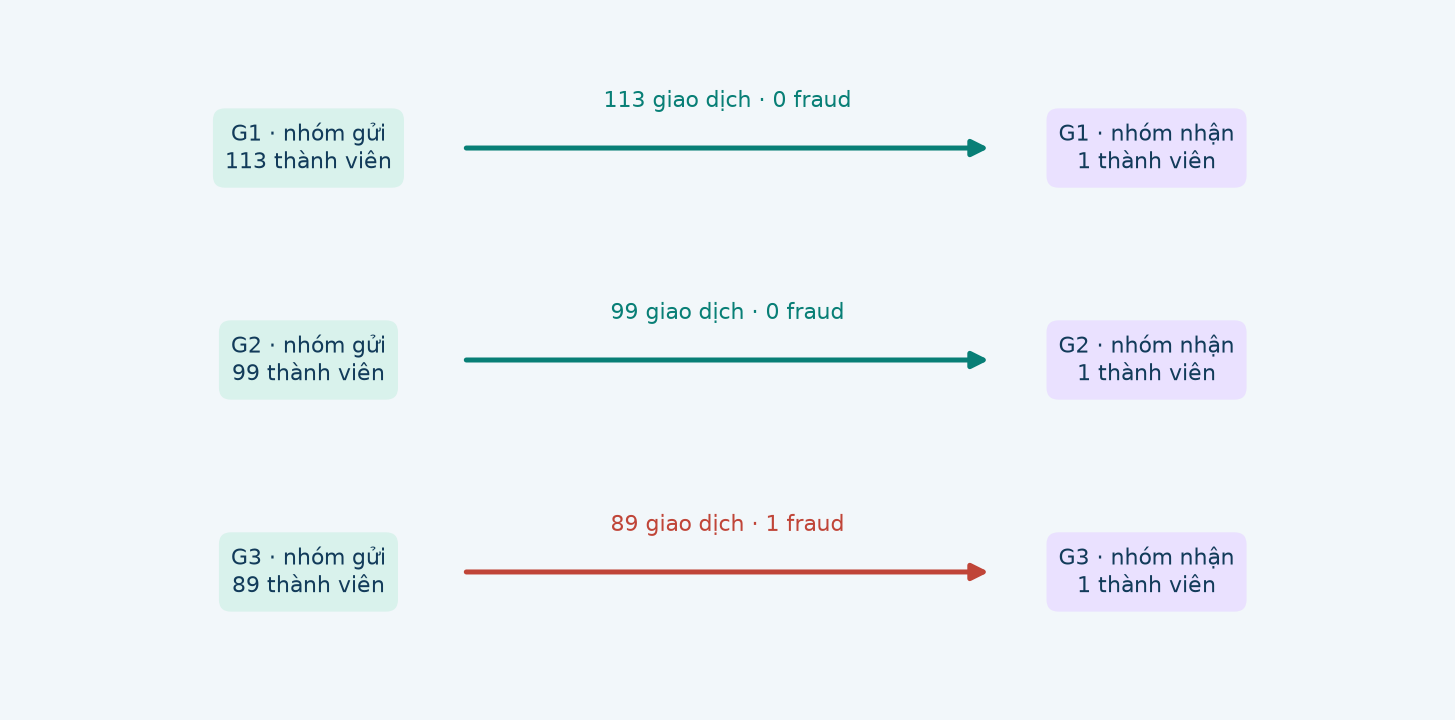

In [17]:
# CODE CHÍNH
def label_endpoints(edges, labels):
    source = labels.select(F.col("id").alias("src"), F.col("label").alias("source_group"))
    target = labels.select(F.col("id").alias("dst"), F.col("label").alias("target_group"))
    return edges.join(source, "src").join(target, "dst")

links = label_endpoints(edges, labels)
internal = links.where("source_group = target_group")
cross_group = links.where("source_group <> target_group")
flows = cross_group.groupBy("source_group", "target_group").agg(
    F.count("*").alias("transactions"), F.sum("amount").alias("amount"), F.sum("isFraud").alias("fraud")
)

*Hình tổng hợp chỉ gồm 6 nhóm thuộc 3 mạng lân cận được chọn. Mỗi ô là một nhóm LPA. Mỗi mũi tên gộp các giao dịch từ nhóm gửi đến nhóm nhận. Đỏ đánh dấu luồng có ít nhất một giao dịch fraud. Số tiền trong bảng theo đơn vị PaySim. Dấu “—” ở tỷ lệ fraud cho biết nhóm không có giao dịch đi ra.*

G1 có **113 thành viên**, cùng gửi 113 giao dịch tới một tài khoản nằm ở nhóm nhận. G2 có **99 giao dịch** nhưng tổng tiền đi ra khoảng **177,89 triệu**, cao hơn khoảng **77,43 triệu** ở G1. G3 có **1 giao dịch fraud trong 89 giao dịch** đi ra. Số thành viên, tổng tiền và số giao dịch fraud trả lời ba câu hỏi khác nhau. Các số đi ra của nhóm gửi và đi vào của nhóm nhận mô tả cùng các giao dịch.

**Phóng to đến mức tài khoản.** Hình dưới đặt các thành viên của nhóm gửi bên trái và tài khoản nhận bên phải để thấy mũi tên đi qua biên nhóm.

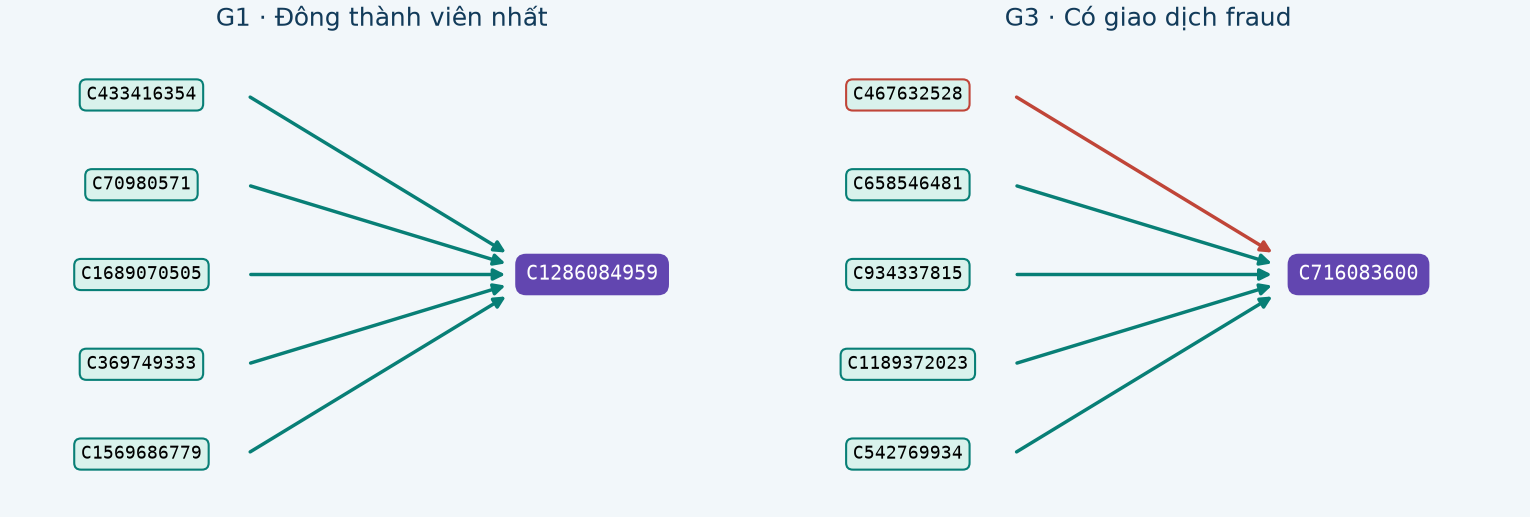

*G1 và G3 hiển thị 5 cạnh mỗi hình. Ô xanh nhạt là thành viên nhóm gửi. Ô tím là tài khoản ở nhóm nhận. Ưu tiên hiển thị cạnh fraud, sau đó chọn các cạnh có số tiền cao. Hướng đi từ trái sang phải.*

Các tài khoản bên trái trong mỗi ví dụ có **chung điểm nhận**. Chúng cùng nhãn LPA sau 5 lượt, dù không giao dịch với nhau. Tài khoản đích chung lại có nhãn khác. Đây là lý do nhóm cần đọc **nhãn cùng với cạnh nội bộ và cạnh qua biên** khi diễn giải kết quả cộng đồng. Từ kết quả LPA, nhóm thử đưa kích thước nhóm và tỷ lệ giao dịch ra ngoài nhóm vào bộ features lịch sử.

### 3.5. Nối các góc nhìn trên cụm A–D

Quay lại bốn tài khoản ở phần mở đầu. Bảng lấy degree trên toàn đồ thị và nhãn LPA của đúng bốn tài khoản. Hình motif trước đó chỉ hiển thị ba giao dịch được chọn.

<table class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th>Đỉnh</th>
      <th>id</th>
      <th>In-degree</th>
      <th>Out-degree</th>
      <th>PageRank</th>
      <th>Nhãn LPA</th>
      <th>Kích thước nhóm LPA</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>A</td>
      <td>C831358900</td>
      <td>0</td>
      <td>1</td>
      <td>0,626485</td>
      <td>4.023.525.067.129.634.816</td>
      <td>58</td>
    </tr>
    <tr>
      <td>B</td>
      <td>C1554009922</td>
      <td>0</td>
      <td>1</td>
      <td>0,626485</td>
      <td>4.023.525.067.129.634.816</td>
      <td>58</td>
    </tr>
    <tr>
      <td>C</td>
      <td>C874023329</td>
      <td>58</td>
      <td>1</td>
      <td>31,512202</td>
      <td>-9.126.548.214.371.095.552</td>
      <td>1</td>
    </tr>
    <tr>
      <td>D</td>
      <td>C1468339976</td>
      <td>35</td>
      <td>0</td>
      <td>45,251021</td>
      <td>-7.717.264.249.832.590.336</td>
      <td>1</td>
    </tr>
  </tbody>
</table>

#### Theo dõi các nhóm degree qua PageRank, motif và LPA

Bảng dưới đổi mức top-K và giữ ties. Với các tài khoản được chọn, notebook giữ **toàn bộ component liên thông** từ CSV, rồi tính lại degree, 10 vòng PageRank, 5 vòng LPA và các vai trò motif. PageRank dùng hệ số chuẩn hóa toàn mạng của lần chạy gốc; cả 10 tài khoản trong file PageRank gốc được đối chiếu đến sai số 1e-10. Motif ở đây đếm cặp cạnh quanh tài khoản trong toàn kỳ, khác phạm vi “giao dịch test” của bảng coverage.

<table class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th>Quy tắc chọn</th>
      <th>Ngưỡng degree</th>
      <th>Tài khoản</th>
      <th>Trùng nhóm out-degree cực đại</th>
      <th>Tài khoản đạt PR từ p99</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>Top 10 inDegree + ties</td>
      <td>97</td>
      <td>10</td>
      <td>0</td>
      <td>10</td>
    </tr>
    <tr>
      <td>Top 25 inDegree + ties</td>
      <td>84</td>
      <td>26</td>
      <td>0</td>
      <td>26</td>
    </tr>
    <tr>
      <td>Top 50 inDegree + ties</td>
      <td>75</td>
      <td>51</td>
      <td>0</td>
      <td>51</td>
    </tr>
    <tr>
      <td>All maximum outDegree</td>
      <td>3</td>
      <td>15</td>
      <td>15</td>
      <td>0</td>
    </tr>
  </tbody>
</table>

<table class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th>Quy tắc chọn</th>
      <th>Tâm fan-in</th>
      <th>Tâm fan-out</th>
      <th>Trung gian relay</th>
      <th>Nhóm LPA một thành viên</th>
      <th>Nhóm đơn LPA (%)</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>Top 10 inDegree + ties</td>
      <td>10</td>
      <td>0</td>
      <td>0</td>
      <td>10</td>
      <td>100,000000</td>
    </tr>
    <tr>
      <td>Top 25 inDegree + ties</td>
      <td>26</td>
      <td>0</td>
      <td>0</td>
      <td>24</td>
      <td>92,307692</td>
    </tr>
    <tr>
      <td>Top 50 inDegree + ties</td>
      <td>51</td>
      <td>0</td>
      <td>0</td>
      <td>43</td>
      <td>84,313725</td>
    </tr>
    <tr>
      <td>All maximum outDegree</td>
      <td>0</td>
      <td>15</td>
      <td>0</td>
      <td>4</td>
      <td>26,666667</td>
    </tr>
  </tbody>
</table>

<table class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th>Quy tắc chọn</th>
      <th>GD vào nhóm</th>
      <th>Fraud ở cạnh vào</th>
      <th>Fraud ở nhóm (%)</th>
      <th>Fraud ở phần còn lại (%)</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>Top 10 inDegree + ties</td>
      <td>1.024,000000</td>
      <td>0</td>
      <td>0,000000</td>
      <td>0,129103</td>
    </tr>
    <tr>
      <td>Top 25 inDegree + ties</td>
      <td>2.449,000000</td>
      <td>2</td>
      <td>0,081666</td>
      <td>0,129100</td>
    </tr>
    <tr>
      <td>Top 50 inDegree + ties</td>
      <td>4.423,000000</td>
      <td>6</td>
      <td>0,135655</td>
      <td>0,129077</td>
    </tr>
  </tbody>
</table>

Đổi mức top-K cho thấy phần nào của nhận định giữ được. Trong các mức đã kiểm tra, nhóm in-degree cao đều đạt PageRank từ p99 và không trùng nhóm out-degree cực đại. Nhưng đặc điểm **nhóm LPA một thành viên** thay đổi: top 10 có 10/10; top 25 kèm ties có 24/26; top 50 kèm ties có 43/51. Vì vậy, nhận định “hub nằm trong nhóm LPA một thành viên” cần giới hạn theo nhóm được xét.

Số cạnh fraud vào nhóm tăng từ 0 lên 2 rồi 6 khi mở rộng nhóm. Để đánh giá ý nghĩa, bảng giữ cả số giao dịch vào nhóm, tỷ lệ fraud và tỷ lệ ở phần còn lại; không suy ra độ rủi ro từ số fraud đơn thuần. Bảng toàn population phía trên còn cho phép đối chiếu cùng loại giao dịch.

“Cao” ở out-degree chỉ là 3 lần xuất hiện. Các hình hub và G1–G3 giải thích cấu trúc của ví dụ; các thống kê population và kiểm tra nhiều ngưỡng cung cấp căn cứ cho nhận định rộng hơn. Những phân tích này mô tả liên hệ với nhãn, không chứng minh quan hệ nhân quả.

**Degree** cho thấy C nhận **58** giao dịch và gửi **1** giao dịch trên toàn mạng. **Motif** cho thấy hai cạnh chuyển tiền được chọn có thể ghép với cạnh `CASH_OUT` đó theo thứ tự thời gian. **LPA** xếp A và B cùng nhóm, còn C và D nằm ở hai nhóm khác. Cùng một giao dịch có thể được nhìn qua mức độ hoạt động của hai đầu, luồng tiền trước đó và quan hệ qua biên nhóm.

Phần 4 sẽ xem thông tin nào đã có tại lúc chấm điểm giao dịch, cách đưa nó vào vector features và cột nào cây quyết định thực sự dùng.

<details>
<summary>Nguồn kết quả và cách chọn ví dụ</summary>
<p>Số liệu toàn mạng và tập đánh giá lấy từ run <code>run_20261024T084918669391Z</code>. Phân vị, tương quan và đối chiếu top 10 PageRank với degree lấy từ output phân tích đã lưu trong <code>PaySIM_full_system.ipynb</code> ở cell <code>analysis-code-centrality</code>. Ví dụ motif và mạng lân cận lấy từ CSV PaySim có SHA-256 khớp đầu vào đã đối chiếu của run gốc.</p>
<p>Nhãn cho các mạng lân cận được kiểm tra cục bộ trên thành phần đã lấy đủ mọi cạnh vào và ra. Việc kiểm tra dùng cùng nhãn khởi tạo, quy tắc chọn nhãn khi bằng phiếu và 5 lượt của LPA gốc. Ba nhóm gửi khớp mã nhóm, kích thước, số cạnh và số fraud trong <code>community_top50.csv</code>. Tên G1, G2 và G3 là tên rút gọn trên hình.</p>
</details>

<a id="features-va-model"></a>

## 4. Features và model

Phần 3 đọc đồ thị để hiểu vai trò của tài khoản, mẫu giao dịch và cộng đồng. Phần này chuyển các quan sát đó thành **đặc trưng (features)** cho từng giao dịch. Câu hỏi là ở thời điểm cần chấm điểm, mô hình đã biết những gì và cây quyết định dùng cột nào để chia nhánh?

### 4.1. Khi chấm điểm, mô hình biết gì?

Lấy một giao dịch `CASH_OUT` thực tế trong dữ liệu ở **giờ 710**. Mã `event_id` dùng để nối dòng giao dịch với dòng features và kết quả chấm điểm. Dòng này sẽ được xem lại ở phần kết quả.

Event ID,Tài khoản gửi,Tài khoản nhận,Giờ mô phỏng,Loại,Số tiền (đơn vị PaySim)
2.012,C415175436,C1774310379,710,CASH_OUT,"10.000.000,00"


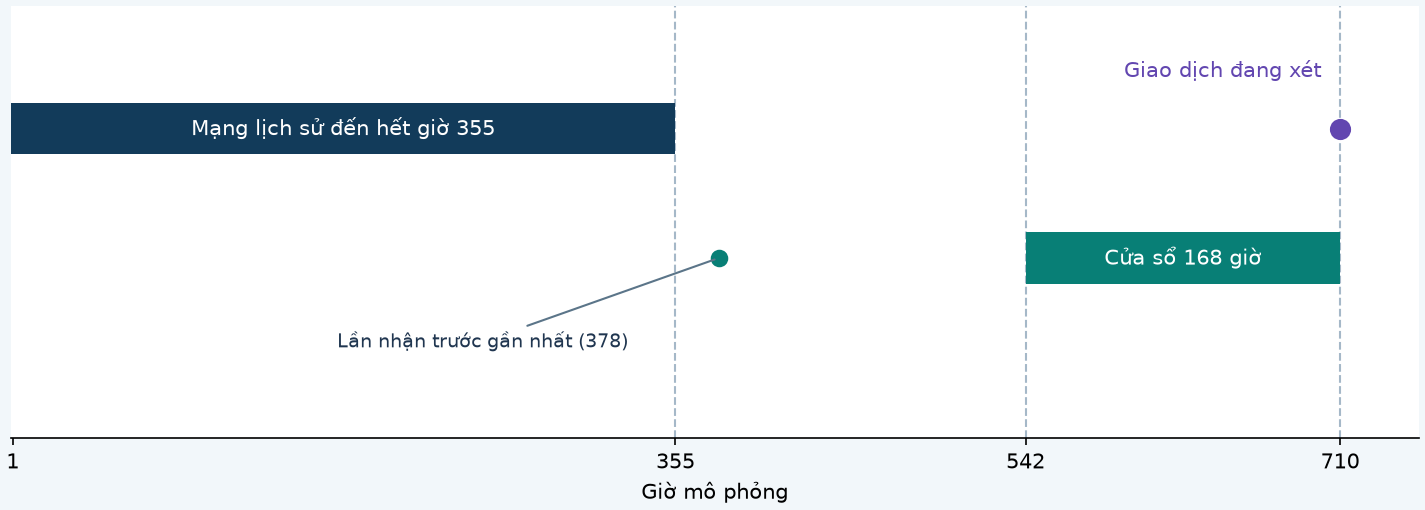

In [18]:
# CODE CHÍNH
def historical_snapshot(transactions, cutoff):
    past = transactions.where(F.col("step") <= cutoff).select("src", "dst")
    ids = past.select(F.col("src").alias("id")).unionByName(past.select(F.col("dst").alias("id"))).distinct()
    past_labels = propagate_labels(ids, past)
    sizes = past_labels.groupBy("label").agg(F.count("*").alias("community_size"))
    links = label_endpoints(past, past_labels)
    stats = links.groupBy(F.col("source_group").alias("label")).agg(
        F.count("*").alias("community_out_transactions"),
        F.avg((F.col("source_group") != F.col("target_group")).cast("double")).alias("community_cross_fraction"),
    )
    return (past_labels.join(sizes, "label").join(stats, "label", "left")
        .join(degree_by_account(ids, past), "id").join(pagerank_by_account(ids, past), "id").fillna(0))

snapshot = historical_snapshot(unlabelled, cutoff=355)
test_block = motif_features.where("step > 355")

Giao dịch đang xét cung cấp `type` và `amount`. Để tính degree, PageRank và cộng đồng, pipeline dùng **snapshot**, tức bản chụp đồ thị đến hết giờ **355**. Để tính motif và lịch sử gần, pipeline tìm các cạnh xuất hiện trước giờ **710**, theo cửa sổ 24 hoặc 168 giờ. Cạnh cùng giờ với giao dịch đang xét được loại khỏi lịch sử vì PaySim ghi thời gian theo giờ.

Trong ví dụ, đầu nhận đã nhận **10 giao dịch** đến hết giờ 355. Lần nhận gần nhất trước giao dịch này là ở giờ **378**. Cửa sổ 168 giờ chỉ tính từ giờ **542 đến 709**, nên `receiver_in_168h = 0`. Hai cột trả lời hai câu hỏi khác nhau về cùng một tài khoản.

Pipeline gắn snapshot theo mã của đầu gửi và đầu nhận, rồi ghép lịch sử theo `event_id`. Kết quả lưu từ lần chạy gốc có **6.362.620 dòng, 6.362.620 ID phân biệt** và **0 dòng lấy snapshot ở cùng giờ hoặc sau giao dịch**.

### 4.2. Từ kết quả đồ thị đến một dòng features

Bảng dưới chọn vài cột từ bốn nhóm. Đọc theo thứ tự **cột lấy từ đâu → giá trị ở giao dịch này → giá trị đó cho biết gì**.

In [19]:
# CODE CHÍNH
snapshot_columns = ["inDegree", "outDegree", "degree", "pagerank", "community_size",
                    "community_cross_fraction", "community_out_transactions"]

def join_snapshot(block, snapshot, cutoff):
    for side in ("src", "dst"):
        endpoint = snapshot.select(
            F.col("id").alias(side), F.lit(1).alias(f"{side}_seen"), F.col("label").alias(f"{side}_group"),
            *[F.col(name).cast("double").alias(f"{side}_{name}") for name in snapshot_columns],
        )
        block = block.join(endpoint, side, "left")
    seen = (F.coalesce("src_seen", F.lit(0)) == 1) & (F.coalesce("dst_seen", F.lit(0)) == 1)
    return (block.withColumn("community_endpoints_seen", seen.cast("double"))
        .withColumn("same_community", (seen & (F.col("src_group") == F.col("dst_group"))).cast("double"))
        .drop("src_group", "dst_group").fillna(0).withColumn("snapshot_as_of", F.lit(cutoff)))

# Mỗi block dùng mạng tính đến hết mốc liền trước.
cutoffs = [135, 206, 239, 303, 355]
bounds = [None, *cutoffs, None]
graph_columns = [f"{side}_{name}" for side in ("src", "dst") for name in [*snapshot_columns, "seen"]]
features = None
for start, stop in zip(bounds[:-1], bounds[1:]):
    block = motif_features
    if stop is not None:
        block = block.where(F.col("step") <= stop)
    if start is None:
        for name in [*graph_columns, "same_community", "community_endpoints_seen"]:
            block = block.withColumn(name, F.lit(0.0))
        block = block.withColumn("snapshot_as_of", F.lit(None).cast("long"))
    else:
        history = historical_snapshot(unlabelled, start)
        block = join_snapshot(block.where(F.col("step") > start), history, start)
    features = block if features is None else features.unionByName(block)

Nhóm,Feature,Giá trị · event 2012,Cách đọc
Giao dịch hiện tại,type_index,1 (CASH_OUT),Mã loại giao dịch do bộ mã hóa từ train tạo
Giao dịch hiện tại,scaled_amount,"3,366297",Số tiền sau chuẩn hóa từ mốc học ở train
Degree và PageRank,dst_inDegree,10,Số giao dịch đã đi vào đầu nhận đến hết giờ 355
Degree và PageRank,dst_pagerank,"5,949286",PageRank đầu nhận trên mạng đến hết giờ 355
Degree và PageRank,src_seen / dst_seen,0 / 1,"Đầu gửi mới, đầu nhận đã xuất hiện trong snapshot"
Motif và lịch sử,receiver_in_168h,0,Số giao dịch đi vào đầu nhận trong 168 giờ trước
Motif và lịch sử,fanin_168h / relay_168h,0 / 0,Số cạnh lịch sử phù hợp với từng mẫu ở giao dịch này
Cộng đồng LPA,dst_community_size,1,Số tài khoản trong nhóm của đầu nhận tại giờ 355
Cộng đồng LPA,community_endpoints_seen,0,Có đủ lịch sử của cả hai đầu để đối chiếu nhóm hay chưa


`type_index = 1` là mã của `CASH_OUT`. Với `scaled_amount`, nhóm chia số tiền cho mốc phân vị 90% của các giao dịch cùng loại và đơn vị tiền trong tập huấn luyện, rồi lấy log để giảm độ chênh giữa các giá trị lớn. Vì vậy **3,366297** là giá trị sau biến đổi của **10 triệu đơn vị PaySim**.

Tại giờ 355, đầu gửi chưa xuất hiện còn đầu nhận đã có trong mạng. Cờ `community_endpoints_seen = 0` báo rằng dữ liệu hiện có thiếu thông tin của một đầu để đối chiếu nhóm. Khi chấm điểm, mô hình dùng các đặc trưng đã tính. `isFraud` được dùng làm nhãn khi huấn luyện và để đối chiếu kết quả khi đánh giá.

### 4.3. Huấn luyện và chọn cấu hình theo thời gian

Nhóm dùng cùng một loại **cây quyết định** cho các bộ features. Cây học các điều kiện chia giao dịch thành những nhóm có tỷ lệ nhãn khác nhau. Fraud ít gặp nên trong quá trình học, giao dịch có nhãn fraud được gán trọng số lớn hơn. Ở lần huấn luyện cuối, có **3.963 fraud trong 5.113.884 giao dịch** và mỗi dòng fraud có trọng số khoảng **35,91 lần** so với một dòng nhãn 0.

Mỗi lượt validation học từ các giao dịch đã xảy ra và kiểm tra trên giai đoạn ngay sau đó. Tập huấn luyện mở rộng dần qua ba lượt.

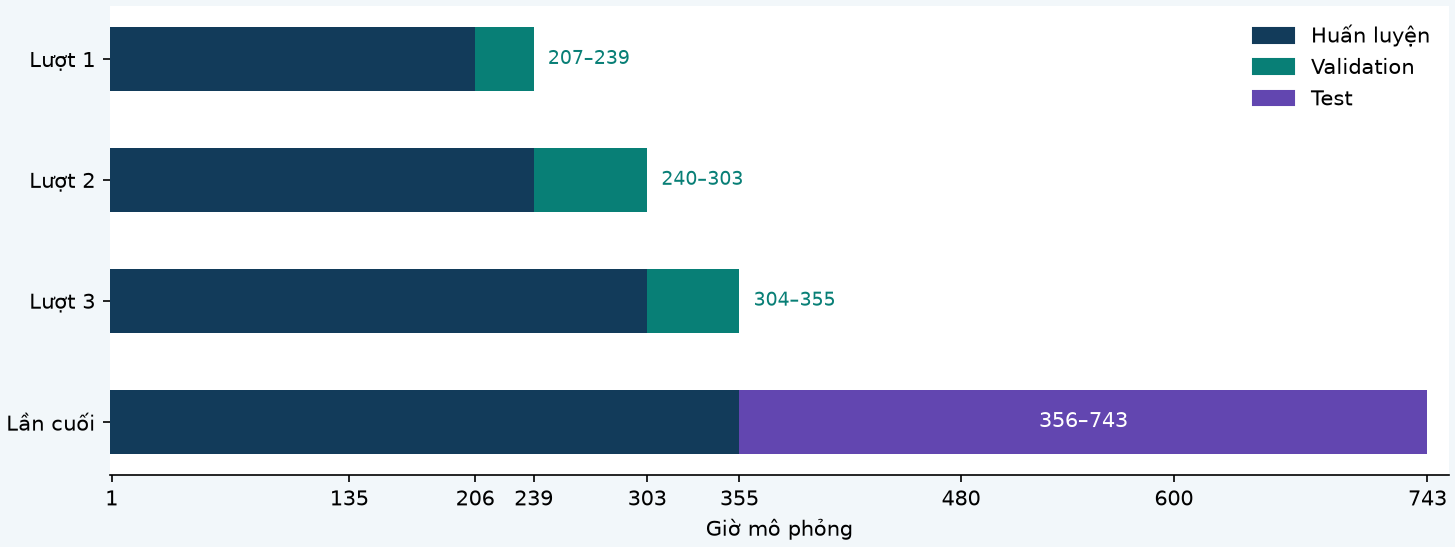

In [20]:
# CODE CHÍNH
from math import sqrt
from pyspark.ml import Pipeline
from pyspark.ml.classification import DecisionTreeClassifier
from pyspark.ml.feature import StringIndexer, VectorAssembler
from pyspark.ml.functions import vector_to_array

def scale_amount(rows, scales):
    rows = rows.join(scales, ["payment_currency", "type"], "left")
    scale = F.greatest(F.coalesce("training_q90", F.lit(1.0)), F.lit(1e-12))
    return (rows.withColumn("scaled_amount", F.log1p(F.least(F.col("amount") / scale, F.lit(1e12))))
        .withColumn("unseen_amount_group", F.col("training_q90").isNull().cast("double"))
        .withColumn("fx_payment", (F.col("payment_currency") != F.col("receiving_currency")).cast("double")))

def fit_tree(features, truth, train_end, columns):
    train = features.where(F.col("step") <= train_end)
    scales = train.where("amount > 0").groupBy("payment_currency", "type").agg(
        F.percentile_approx("amount", 0.9, 10_000).alias("training_q90")
    )
    train = scale_amount(train, scales).join(truth, "event_id")
    counts = train.agg(F.count("*").alias("n"), F.sum("isFraud").alias("p")).first()
    weight = sqrt((counts.n - counts.p) / counts.p)
    train = train.withColumn("_weight", F.when(F.col("isFraud") == 1, weight).otherwise(1.0))
    encoder = StringIndexer(inputCols=["type", "payment_currency"],
        outputCols=["type_index", "currency_index"], stringOrderType="alphabetAsc", handleInvalid="keep")
    assembler = VectorAssembler(inputCols=columns, outputCol="features")
    tree = DecisionTreeClassifier(labelCol="isFraud", featuresCol="features", weightCol="_weight",
        maxDepth=5, maxBins=64, minInstancesPerNode=50, seed=2026)
    return Pipeline(stages=[encoder, assembler, tree]).fit(train), scales

def score_tree(model, scales, rows):
    scored = model.transform(scale_amount(rows, scales))
    return scored.select("event_id", "step", vector_to_array("probability")[1].alias("risk_score"))

Với từng bộ features và ngưỡng cảnh báo, nhóm tính F1 ở ba lượt validation. F1 cân bằng giữa tỷ lệ cảnh báo đúng và tỷ lệ fraud được phát hiện. Sau khi chọn theo **F1 validation trung bình**, nhóm khóa bộ cột và ngưỡng, huấn luyện lại đến hết giờ **355**, rồi đánh giá trên giờ **356–743**.

In [21]:
# CODE CHÍNH
import pandas as pd

transaction = ["type_index", "currency_index", "scaled_amount", "unseen_amount_group", "fx_payment"]
centrality = [f"{side}_{name}" for side in ("src", "dst")
              for name in ("inDegree", "outDegree", "degree", "pagerank", "seen")]
community = [f"{side}_{name}" for side in ("src", "dst") for name in (
    "community_size", "community_cross_fraction", "community_out_transactions"
)] + ["same_community", "community_endpoints_seen"]
motif = [f"{name}_{h}h" for h in (24, 168) for name in (
    "sender_in", "sender_out", "receiver_in", "receiver_out", "fanin", "fanout", "relay", "reciprocal"
)] + ["cycle3_count", "cycle3_best_ratio", "cycle3_min_gap_seconds"]
extra = {
    "transaction_only": [], "transaction_novelty": ["src_seen", "dst_seen"],
    "transaction_centrality": centrality, "motif_assisted": motif,
    "transaction_community": community, "full_fusion": centrality + motif + community,
    "without_centrality": motif + community, "without_motifs": centrality + community,
    "without_community": centrality + motif,
}

def score_bins(scored, truth):
    return (scored.join(truth, "event_id").groupBy("risk_score")
        .agg(F.count("*").alias("transactions"), F.sum("isFraud").alias("positives")).toPandas())

def metrics_at_threshold(bins, threshold):
    alerted = bins.loc[bins.risk_score >= threshold]
    tp = int(alerted.positives.sum())
    alerts = int(alerted.transactions.sum())
    fraud = int(bins.positives.sum())
    fp, fn = alerts - tp, fraud - tp
    tn = int(bins.transactions.sum()) - tp - fp - fn
    return {"TP": tp, "FP": fp, "FN": fn, "TN": tn, "alerts": alerts,
            "precision": tp / alerts if alerts else None,
            "recall": tp / fraud if fraud else None,
            "F1": 2 * tp / (alerts + fraud) if alerts + fraud else None}

folds = [(206, 239), (239, 303), (303, 355)]
thresholds = [0.001, 0.005, 0.01, 0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 0.9, 0.99]
rows = []
for train_end, validation_end in folds:
    validation = features.where((F.col("step") > train_end) & (F.col("step") <= validation_end))
    for family, extra_columns in extra.items():
        model, scales = fit_tree(features, truth, train_end, transaction + extra_columns)
        bins = score_bins(score_tree(model, scales, validation), truth)
        for threshold in thresholds:
            rows.append({"family": family, "threshold": threshold, **metrics_at_threshold(bins, threshold)})

ranking = pd.DataFrame(rows).groupby(["family", "threshold"], as_index=False).agg(
    mean_F1=("F1", "mean"), worst_F1=("F1", "min"), FP=("FP", "sum")
)
complexity = {"transaction_only": 0, "transaction_novelty": 0, "transaction_centrality": 2,
    "motif_assisted": 2, "transaction_community": 2, "full_fusion": 4,
    "without_centrality": 3, "without_motifs": 3, "without_community": 3}
ranking["complexity"] = ranking.family.map(complexity)
ranking = ranking.sort_values(["mean_F1", "worst_F1", "FP", "complexity", "threshold"],
                              ascending=[False, False, True, True, False])
selected = ranking.iloc[0]
baseline = ranking.loc[ranking.family == "transaction_only"].iloc[0]

Mô hình,Cột đầu vào,F1 trung bình qua 3 lượt validation,Ngưỡng đã chốt
Baseline,5 cột giao dịch hiện tại,"7,01%","0,7"
Model được chọn,5 giao dịch + 19 motif/lịch sử + 8 cộng đồng,"15,84%","0,7"


Baseline dùng thông tin của giao dịch hiện tại. Model được chọn, `without_centrality`, bổ sung nhóm motif/lịch sử và cộng đồng. Cả hai dùng ngưỡng **0,70** đã chốt trên validation. Khi điểm của cây đạt ngưỡng, giao dịch được đưa vào danh sách cảnh báo. Bảng này giải thích **cách chọn cấu hình**. Phần 5 sẽ đối chiếu hiệu quả của hai model trên tập test.

### 4.4. Cây thực sự dùng những cột nào?

Có ba bước cần phân biệt. Nhóm chuẩn bị các cột cho thí nghiệm. Mỗi cấu hình đưa một danh sách cột vào vector của cây. Khi học, cây chọn một số cột để đặt điều kiện chia nhánh.

In [22]:
# CODE CHÍNH
selected_columns = transaction + extra["without_centrality"]
selected_model, selected_scales = fit_tree(features, truth, 355, selected_columns)
# VectorAssembler giữ đúng thứ tự này, 5 + 19 + 8 = 32 cột.
assert selected_model.stages[1].getInputCols() == selected_columns

Nhóm,Cột trong thí nghiệm,Cột cấp cho model được chọn,Cột cây dùng để chia nhánh
Giao dịch hiện tại,5,5,2
Degree và PageRank,10,0,0
Motif và lịch sử giao dịch,19,19,1
Cộng đồng LPA,8,8,0
Tổng,42,32,3


Vị trí,Feature,Giá trị
1,type_index,"1,000000"
2,currency_index,"0,000000"
3,scaled_amount,"3,366297"
4,unseen_amount_group,"0,000000"
5,fx_payment,"0,000000"
6,sender_in_24h,"0,000000"
7,sender_out_24h,"0,000000"
8,receiver_in_24h,"0,000000"
9,receiver_out_24h,"0,000000"
10,fanin_24h,"0,000000"


Cấu hình được chọn nhận **32 cột**, trong đó có **8 cột cộng đồng**. Cây cuối dùng **3 cột** để chia nhánh. Degree và PageRank được thử ở các cấu hình khác. Các cột cộng đồng có mặt trong vector của cây cuối, nhưng cây chia nhánh bằng hai cột giao dịch và một cột lịch sử đầu nhận.

In [23]:
# CODE CHÍNH
tree = selected_model.stages[-1]
used_features = {
    name: importance for name, importance in zip(selected_columns, tree.featureImportances)
    if importance > 0
}

Feature cây dùng,Thông tin,Giá trị · event 2012,Tỷ trọng tiêu chí chia nhánh
receiver_in_168h,Đầu nhận đã nhận bao nhiêu giao dịch trong 168 giờ trước,"0,000000","46,50%"
scaled_amount,Số tiền chuẩn hóa theo loại giao dịch và đơn vị tiền,"3,366297","27,25%"
type_index,Mã của loại giao dịch hiện tại,"1,000000","26,25%"


`receiver_in_168h` là cột lịch sử duy nhất được cây cuối dùng. Nó đếm giao dịch đi vào đầu nhận, kể cả khi giao dịch trước đó đến từ cùng nguồn. Fan-in yêu cầu nguồn khác, còn relay cần tài khoản trung gian và cặp loại giao dịch phù hợp. Tỷ trọng **46,50%** cho biết phần của `receiver_in_168h` trong tiêu chí chia nhánh của cây đã huấn luyện.

Với event 2012, cây sẽ dùng các giá trị trên để đi qua những nhánh phù hợp với giao dịch. Phần 5 sẽ mở đường đi đó, rồi so sánh cả trường hợp bắt đúng, cảnh báo sai và bỏ sót.

<details>
<summary>Nguồn kết quả</summary>
<p>Danh sách cột, trọng số huấn luyện, tỷ trọng chia nhánh và quy tắc đã chốt lấy từ các artifact của run <code>run_20261024T084918669391Z</code>. Vector và giá trị snapshot của event 2012 lấy từ output đã lưu của <code>analysis-code-feature-bridge</code> trong notebook full-system. Giao dịch gốc, số cạnh vào và cửa sổ lịch sử của hai đầu được đối chiếu với CSV PaySim.</p>
</details>

<a id="ket-qua-va-ket-luan"></a>

## 5. Kết quả và kết luận

Trên cùng **1.248.736 giao dịch test** từ giờ **356 đến 743**, có **4.250 giao dịch fraud**. Baseline và model được chọn đều cảnh báo khi điểm từ **0,70** trở lên. Ta xem lần lượt chất lượng cảnh báo, đường đi của ba giao dịch và kết quả ở từng giai đoạn.

### 5.1. Mô hình mới bắt thêm bao nhiêu fraud?

**Precision** đo tỷ lệ cảnh báo đúng. **Recall** đo tỷ lệ fraud được phát hiện. **F1** cân bằng hai tỷ lệ tại ngưỡng đã chốt. **AP** đo chất lượng xếp hạng theo điểm khi xét nhiều ngưỡng. Pipeline huấn luyện lại đến giờ 355 và chấm điểm tập test bằng cấu hình đã chọn trên validation.

In [24]:
# CODE CHÍNH
baseline_model, baseline_scales = fit_tree(features, truth, 355, transaction)
test = features.where("step > 355")
baseline_scores = score_tree(baseline_model, baseline_scales, test)
selected_scores = score_tree(selected_model, selected_scales, test)

def average_precision(bins):
    bins = bins.sort_values("risk_score", ascending=False)
    precision = bins.positives.cumsum() / bins.transactions.cumsum()
    return (precision * bins.positives / bins.positives.sum()).sum()

test_metrics = {}
for name, scores, rule in [("baseline", baseline_scores, baseline), ("selected", selected_scores, selected)]:
    bins = score_bins(scores, truth)
    test_metrics[name] = {**metrics_at_threshold(bins, rule.threshold), "AP": average_precision(bins)}

Mô hình,Precision,Recall,F1,AP
Baseline,"81,01%","19,67%","31,65%","17,00%"
Model được chọn,"58,12%","26,09%","36,02%","26,58%"


Mô hình,Cảnh báo,Phát hiện đúng (TP),Cảnh báo sai (FP),Bỏ sót (FN),Loại đúng (TN)
Baseline,1.032,836,196,3.414,1.244.290
Model được chọn,1.908,1.109,799,3.141,1.243.687


Trong lần chạy gốc, F1 tăng từ **31,65% lên 36,02%** và AP từ **17,00% lên 26,58%**. Model được chọn bắt thêm **273 fraud** so với baseline. Đổi lại, danh sách cần xem xét có thêm **876 cảnh báo**, gồm thêm **603 cảnh báo sai**. Precision vì thế giảm từ **81,01% xuống 58,12%**. Với ngưỡng 0,70, model vẫn bỏ sót **3.141 trong 4.250 fraud**.

### 5.2. Vì sao cây cảnh báo hoặc bỏ sót từng giao dịch?

Ba ví dụ dưới đây lấy từ lần chạy gốc. TP quay lại **event 2012** ở phần 4. FP được chọn vì cùng đi đến lá với TP nhưng nhãn khác. FN là một giao dịch fraud có điểm gần ngưỡng và đi qua nhánh dùng lịch sử đầu nhận.

Để giải thích từng ví dụ, nhóm đối chiếu giá trị feature với điều kiện của **cây đã huấn luyện**, rồi so điểm tại lá với ngưỡng **0,70**.

Trường hợp,Event ID,Giờ,Loại,Số tiền PaySim,scaled_amount,receiver_in_168h,Điểm,Cảnh báo,Nhãn fraud
TP · Phát hiện đúng,2.012,710,CASH_OUT,"10.000.000,00","3,366297",0,"0,938917",Có,1
FP · Cảnh báo sai,395.137.001.033,376,CASH_OUT,"785.463,88","1,162221",0,"0,938917",Có,0
FN · Bỏ sót,670.014.914.404,543,TRANSFER,"2.558.618,27","0,896949",0,"0,658297",Không,1


Case,Bước,Feature,Giá trị,Điều kiện đi trái,Nhánh thực tế
TP,1,scaled_amount,"3,366297","scaled_amount ≤ 1,15178",Không · phải
TP,2,type_index,CASH_OUT,"Loại thuộc {CASH_IN, DEBIT, PAYMENT, TRANSFER}",Không · phải
FP,1,scaled_amount,"1,162221","scaled_amount ≤ 1,15178",Không · phải
FP,2,type_index,CASH_OUT,"Loại thuộc {CASH_IN, DEBIT, PAYMENT, TRANSFER}",Không · phải
FN,1,scaled_amount,"0,896949","scaled_amount ≤ 1,15178",Có · trái
FN,2,type_index,TRANSFER,"Loại thuộc {CASH_IN, CASH_OUT, DEBIT, PAYMENT}",Không · phải
FN,3,receiver_in_168h,0,"receiver_in_168h ≤ 0,5",Có · trái
FN,4,scaled_amount,"0,896949","scaled_amount ≤ 0,10178",Không · phải
FN,5,scaled_amount,"0,896949","scaled_amount ≤ 0,67735",Không · phải


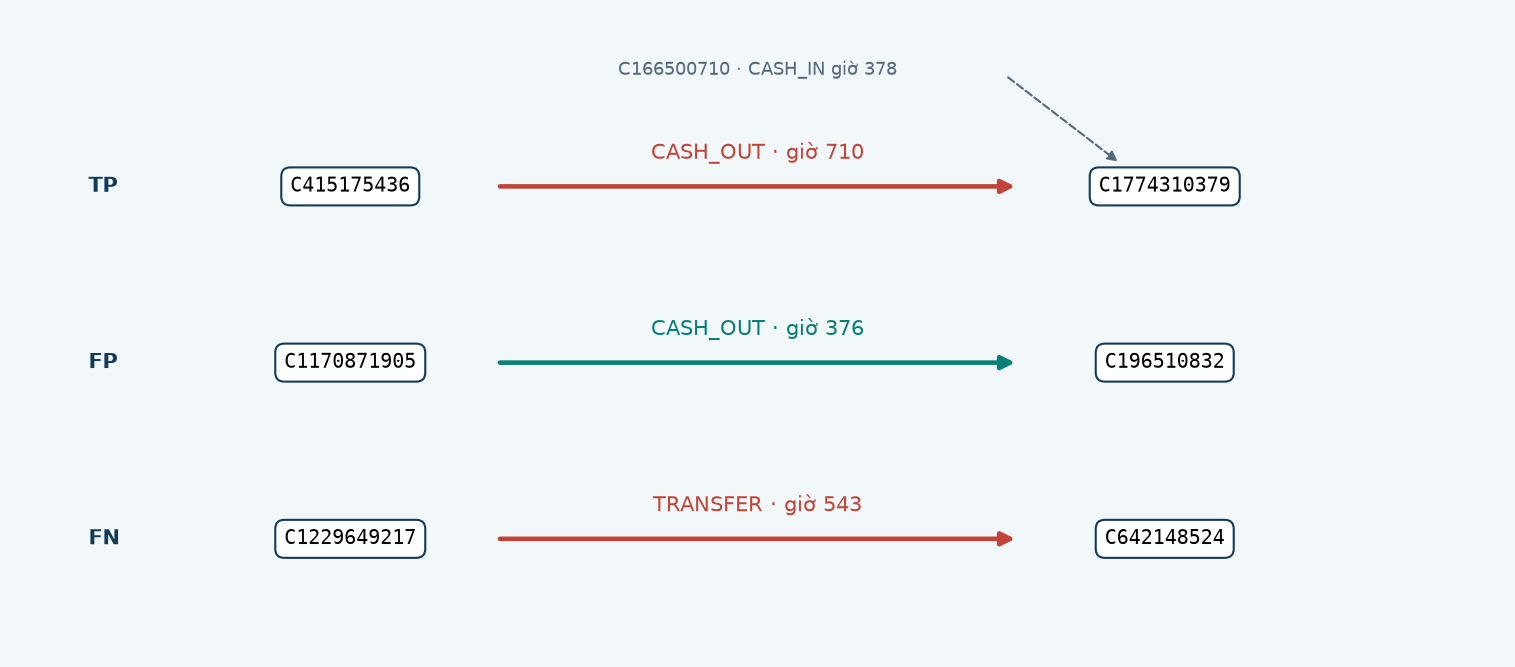

In [25]:
# CODE CHÍNH
from math import log1p

# Các điểm chia và điểm tại lá trích từ cây đã huấn luyện.
splits = {
    0: ('scaled_amount', 1.151782348093285, 1, 10),
    1: ('type_index', ('CASH_IN', 'CASH_OUT', 'DEBIT', 'PAYMENT'), 2, 3),
    3: ('receiver_in_168h', 0.5, 4, 9),
    4: ('scaled_amount', 0.10177732205329212, 5, 6),
    6: ('scaled_amount', 0.6773512964455168, 7, 8),
    10: ('type_index', ('CASH_IN', 'DEBIT', 'PAYMENT', 'TRANSFER'), 11, 16),
    11: ('type_index', ('CASH_IN', 'DEBIT', 'PAYMENT'), 12, 13),
    13: ('receiver_in_168h', 0.5, 14, 15),
}
leaves = {
    2: 0.00958956511005541,
    5: 0.6513443684938433,
    7: 0.4650312255266671,
    8: 0.6582966206507004,
    9: 0.00040143941605177524,
    12: 0.0,
    14: 0.7904492161821861,
    15: 0.0,
    16: 0.9389174204234455,
}
q90 = {"CASH_OUT": 357_512.51, "TRANSFER": 1_762_000.87}
cases = [
    (2012, 'CASH_OUT', 10000000.0, 710, [212, 228, 229, 254, 256, 260, 278, 308, 333, 352, 378]),
    (395137001033, 'CASH_OUT', 785463.88, 376, []),
    (670014914404, 'TRANSFER', 2558618.27, 543, []),
]

for event_id, kind, amount, step, past_steps in cases:
    row = {"scaled_amount": log1p(amount / q90[kind]), "type_index": kind,
           "receiver_in_168h": sum(step - 168 <= t < step for t in past_steps)}
    node = 0
    while node in splits:
        feature, condition, left, right = splits[node]
        go_left = row[feature] in condition if isinstance(condition, tuple) else row[feature] <= condition
        node = left if go_left else right
    risk_score = leaves[node]
    print(event_id, risk_score, risk_score >= 0.70)

*Mỗi hàng trong hình là một giao dịch đang xét. Mũi tên đỏ có `isFraud = 1`, xanh có nhãn 0. Cạnh xám đứt là lần nhận trước gần nhất của đầu nhận TP. Cạnh đó ở giờ 378, ngoài cửa sổ 168 giờ trước giờ 710. Hai đầu nhận còn lại chưa có cạnh vào trước giao dịch đang xét.*

- **TP:** Giao dịch `CASH_OUT` 10 triệu đơn vị PaySim có `scaled_amount` vượt điểm chia đầu tiên. Cây đi tiếp theo loại `CASH_OUT`, cho điểm **0,938917** và phát cảnh báo đúng.
- **FP:** Giao dịch `CASH_OUT` khoảng 785 nghìn cũng vừa vượt điểm chia đầu tiên. Cây đi đến **cùng lá và cùng điểm** với TP. Trong CSV, giao dịch này mang nhãn 0 nên cảnh báo là sai.
- **FN:** Giao dịch `TRANSFER` khoảng 2,56 triệu được chuẩn hóa bằng mốc riêng của `TRANSFER`, nên rơi sang nhánh `scaled_amount ≤ 1,15178`. Sau khi xét loại, số cạnh vào đầu nhận bằng 0 và một điểm chia về số tiền, cây dừng ở điểm **0,658297**. Điểm dưới 0,70 nên giao dịch fraud này bị bỏ sót.

### 5.3. Hiệu quả thay đổi thế nào theo thời gian?

Chia tập test thành năm khoảng liên tiếp theo các mốc đã lưu. Cả hai model được đánh giá trên cùng giao dịch ở mỗi khoảng và giữ nguyên ngưỡng.

Giờ mô phỏng,Giao dịch,Fraud,Tỷ lệ fraud,F1 baseline,F1 model được chọn,Precision model,Recall model
356–375,254.687,226,"0,089%","28,48%","28,57%","30,35%","26,99%"
376–395,266.247,216,"0,081%","29,80%","27,05%","24,26%","30,56%"
396–403,271.053,116,"0,043%","27,03%","35,35%","42,68%","30,17%"
404–526,207.968,1.336,"0,642%","34,04%","40,90%","77,62%","27,77%"
527–743,248.781,2.356,"0,947%","31,12%","35,65%","65,83%","24,45%"


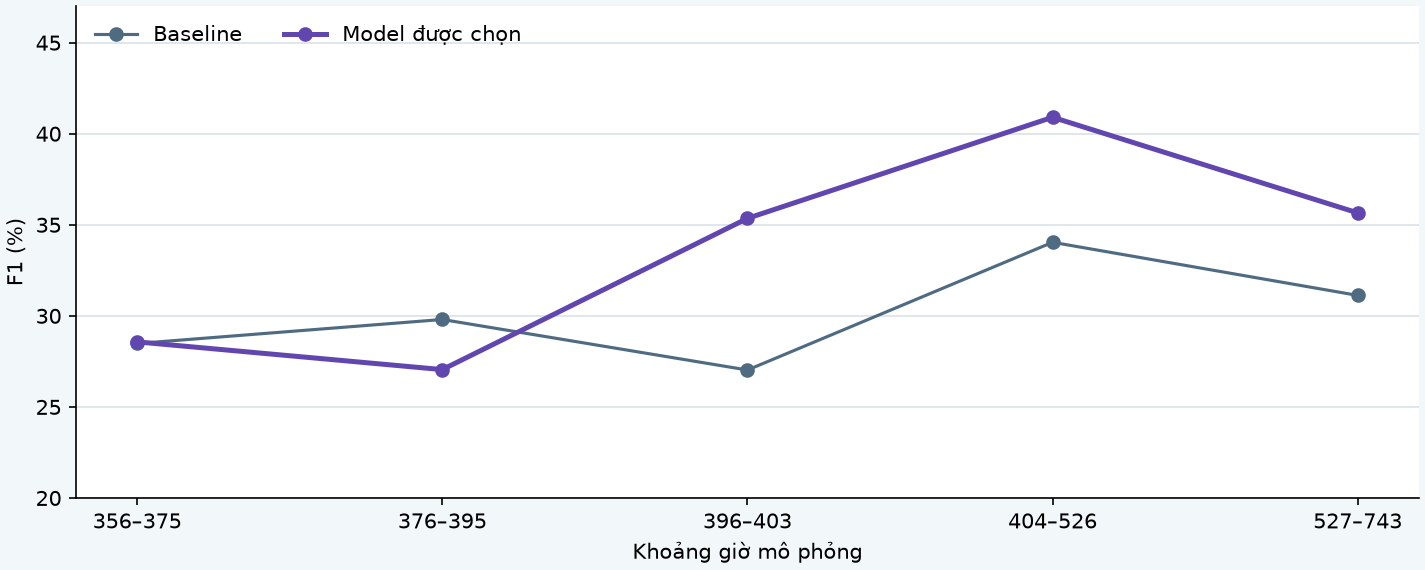

In [26]:
# CODE CHÍNH
cutoffs = [375, 395, 403, 526]
period = sum((F.col("step") > cutoff).cast("int") for cutoff in cutoffs)
timeline_metrics = []
for name, scores, rule in [("baseline", baseline_scores, baseline), ("selected", selected_scores, selected)]:
    groups = (scores.withColumn("period", period).join(truth, "event_id")
        .groupBy("period", "risk_score").agg(
            F.count("*").alias("transactions"), F.sum("isFraud").alias("positives")
        ).toPandas())
    for i, bins in groups.groupby("period"):
        timeline_metrics.append({"model": name, "period": i, **metrics_at_threshold(bins, rule.threshold)})

F1 của model được chọn dao động từ **27,05% đến 40,90%**, cao hơn baseline ở **4 trong 5 khoảng**. Ở giờ **376–395**, model bắt được tỷ lệ fraud cao hơn baseline nhưng precision thấp hơn, khiến F1 giảm. Hai khoảng cuối có **3.692/4.250 fraud**, khoảng **86,9%** tổng fraud của tập test. Như EDA cho thấy, phân bố nhãn thay đổi nhiều theo thời gian. Kết quả chung cần được đọc cùng từng khoảng để thấy khi nào lợi ích phát hiện thêm đi kèm nhiều cảnh báo sai.

### 5.4. Kết luận

1. **Đồ thị giúp đọc cấu trúc giao dịch.** Degree và PageRank chỉ ra những điểm tập trung giao dịch. Motif cho thấy cách nhiều giao dịch nối thành một mẫu. LPA làm rõ nhóm nào có chung đối tác và giao dịch đi qua biên nhóm ra sao.
2. **Cây được chọn dùng một phần thông tin đồ thị.** Trong 32 cột được cấp, cây dùng loại giao dịch, số tiền chuẩn hóa và số giao dịch từng đi vào đầu nhận trong 168 giờ. PageRank và các cột LPA hữu ích để mô tả mạng, còn cải thiện của cây trong thử nghiệm này đi cùng đặc trưng lịch sử đầu nhận.
3. **Hiệu quả có đánh đổi.** Model được chọn tăng recall, F1 và AP trên tập test theo thời gian của PaySim. Danh sách cảnh báo dài hơn, tỷ lệ cảnh báo đúng thấp hơn và nhiều fraud vẫn bị bỏ sót. Kết quả phản ánh dữ liệu mô phỏng và tập đánh giá nội bộ của dự án.

Khi trình bày các điểm nổi bật, có thể quay lại **cụm A–D** để giải thích đồ thị giúp đọc dữ liệu, và **event 2012** để giải thích mô hình dùng features khi đưa ra cảnh báo.

### Mở rộng khi hỏi đáp

**Nếu chỉ xem được một số giao dịch.** Bảng giữ cùng số lượt kiểm tra cho hai mô hình và chọn các giao dịch có điểm cao nhất. Cách đọc này phù hợp khi đã biết đội kiểm tra xử lý được bao nhiêu giao dịch.

In [27]:
# CODE CHÍNH
# Cùng K cho hai model. event_key và event_id xử lý các điểm bằng nhau.
K = 1_249
content_key = F.sha2(F.to_json(F.struct(
    "amount", "dst", "payment_currency", "receiving_currency", "src", "step", "type"
)), 256)
context = unlabelled.select("event_id", content_key.alias("event_key"))
for scores in (baseline_scores, selected_scores):
    reviewed = scores.join(context, "event_id").orderBy(F.desc("risk_score"), "event_key", "event_id").limit(K)
    fraud_found = reviewed.join(truth, "event_id").agg(F.sum("isFraud")).first()[0]

Số giao dịch được xem,Fraud · baseline,Fraud · model được chọn,Precision · model được chọn,Recall · model được chọn
1.249,844,900,"72,06%","21,18%"
6.244,1.014,1.523,"24,39%","35,84%"
12.488,1.120,2.044,"16,37%","48,09%"


**Nếu tài khoản chưa có trong snapshot.** Phân nhóm theo hai đầu nameOrig và nameDest tại giờ 355. Nhóm đã thấy cả hai đầu chỉ có 6 fraud, nên cần đọc recall cùng số giao dịch thực tế.

In [28]:
# CODE CHÍNH
endpoints = test.select("event_id", "src_seen", "dst_seen")
history = (selected_scores.join(endpoints, "event_id").join(truth, "event_id")
    .withColumn("seen_count", F.col("src_seen") + F.col("dst_seen")))
by_history = history.groupBy("seen_count").agg(
    F.count("*").alias("transactions"), F.sum("isFraud").alias("fraud"),
    F.count_if(F.col("risk_score") >= 0.70).alias("alerts"),
    F.count_if((F.col("risk_score") >= 0.70) & (F.col("isFraud") == 1)).alias("TP"),
)

Hai đầu tại snapshot,Giao dịch,Fraud,Cảnh báo,TP,Recall
Đã thấy cả hai,1.593,6,2,2,"33,33%"
Chưa thấy cả hai,600.655,2.899,984,591,"20,39%"
Chưa thấy một đầu,646.488,1.345,922,516,"38,36%"


<details>
<summary>Nguồn và phạm vi kiểm tra</summary>
<p>So sánh model được tính lại từ các nhóm điểm trong <code>pr_curve_*.csv</code> và đối chiếu với <code>test_metrics.csv</code> của run <code>run_20261024T084918669391Z</code>. Các khoảng thời gian, ngân sách xem xét và nhóm lịch sử lấy từ <code>test_temporal_stability.csv</code>, <code>review_budgets.csv</code> và <code>selected_cold_start.csv</code>.</p>
<p>Cây, mã loại và mốc chuẩn hóa được đọc từ Parquet trong bản lưu model rồi kiểm SHA-256 theo danh mục artifact của run gốc. Ba giao dịch và các cạnh lịch sử được đối chiếu với CSV PaySim. Điểm tính lại trong notebook được so với điểm dự đoán đã lưu.</p>
</details>

<details>
<summary>Dữ liệu nằm trong notebook và phạm vi tính lại</summary>

Các bảng phân tích chạy từ dữ liệu được nhúng trong ô đầu tiên, kèm SHA-256 và nguồn. `account_joint_degree.csv` có một dòng cho mỗi tổ hợp tiền tố mã × in-degree × out-degree, với số tài khoản trên **toàn mạng**. `endpoint_census.csv` giữ số giao dịch và tổng amount theo đầu orig/dest × degree × loại × nhãn. `step_type_label_counts.csv` giữ số đếm theo từng giờ × loại × nhãn. Đây là dữ liệu ở mức ô đếm, trước khi tạo các nhóm và tỷ lệ trên slide.

Phân phối amount giữ các giá trị theo cent cùng tần suất, nên code tính được phân vị tuyến tính mà không nhập sẵn p50/p90/p99. Các phép tổng hợp không cần danh tính từng tài khoản trong toàn mạng. Danh tính và đầy đủ giao dịch của các component được chọn được giữ riêng để tính lại thuật toán, soi motif và kiểm tra cộng đồng. Code kiểm tra số tài khoản thỏa từng ngưỡng so với phân bố toàn mạng.

CSV kết quả thuật toán và Parquet của cây đến từ lần chạy hệ thống gốc. Code đọc các output này để hậu kiểm và tái hiện điểm của ví dụ; Run All của bản thuyết trình không chạy lại pipeline Spark trên 6,36 triệu dòng. Các hình giữ nguyên output PNG đã lưu. Chỉ cần gửi một file `.ipynb`; xem output không cần chạy, còn tính lại các bảng dùng Python cùng NumPy, pandas, IPython và PyArrow.

</details>